### Desafio 3 - Enfermedad en la sangre

- Nombre: Jose Ignacio Kuoman Jimenez
- Generacion: G76

#### Descripción

En este desafío utilizaremos una base de datos recolectada en un laboratorio de donación de sangre, en la que contamos con información de diferentes mediciones incluido el sexo del donador y un indicador de donador sospechoso. Las variables regresoras son:

1. **X (Patient ID/No.):** Número o identificación única asociada a cada paciente en la base de datos.
2. **Category (diagnosis):** Categoría que indica el diagnóstico relacionado con la hepatitis C para cada paciente.
3. **Age (in years):** Edad del paciente en años al momento de la detección o registro en la base de datos.
4. **Sex (f,m):** Género del paciente, indicado por "f" para femenino y "m" para masculino.
5. **ALB:** Albúmina, una proteína producida por el hígado. Los niveles de albúmina pueden indicar la función hepática.
6. **ALP:** Fosfatasa alcalina, una enzima que puede estar relacionada con la función hepática y otros procesos.
7. **ALT:** Alanina aminotransferasa, una enzima que puede indicar daño hepático.
8. **AST:** Aspartato aminotransferasa, una enzima que también puede indicar daño hepático.
9. **BIL:** Bilirrubina, un pigmento amarillo que puede aumentar en casos de problemas hepáticos.
10. **CHE:** Colinesterasa, una enzima que puede estar asociada con la función hepática y otros procesos.
11. **CHOL:** Colesterol, un lípido que puede estar relacionado con la salud del hígado.
12. **CREA:** Creatinina, un producto de desecho que se filtra a través de los riñones.
13. **GGT:** Gamma-glutamil transferasa, una enzima que puede estar relacionada con la función hepática.
14. **PROT:** Proteínas totales, que pueden incluir varias proteínas, como albúmina y globulinas.

La variable objetivo es **Category**, y almacena las siguientes categorías: '0=Blood Donor', '0s=suspect Blood Donor', '1=Hepatitis', '2=Fibrosis', '3=Cirrhosis'

Aplicando los conceptos y herramientas aprendidas hasta ahora, deberás realizar las siguientes tareas:

#### Pregunta 1

1. Importa las librerías necesarias para entrenar modelos de regresión logística con validación cruzada y Extreme Gradient Boosting, carga los datos y prepáralos. Para ello:

   a. elimina la columna 'Unnamed: 0'.
   
   b. codifica la variable objetivo **Category** en dos categorías: una para Category='0=Blood Donor', a la que debes asociar valor 0, y un 1 para los demás valores. Asigna estos valores en una nueva columna llamada **target**.
   
   c. codifica en otra columna, con nombre **suspect**, con valor 1 cuando Category='0s=suspect Blood Donor', y asigna 0 en caso contrario. Elimina finalmente la columna Category.
   
   d. Revisa si la base de datos contiene valores ausentes. En caso que sea así, aplica los siguientes criterios:
      
      - i. si el porcentaje de valores ausentes para alguna variable es menor a 1%, entonces elimina las filas que contengan estos valores ausentes.
      
      - ii. si el porcentaje de valores ausentes es mayor, entonces reemplaza estos por el promedio según la clase a la que pertenezca el valor ausente.
   
   e. Realiza un análisis descriptivo para cada variable regresora, usando gráficos para representar distribuciones y boxplot para revisar posibles outliers. Construye un heatmap que muestre las correlaciones entre las variables regresoras y describe.
   
   f. Transforma las variables regresoras por medio de la estandarización. Muestra el antes y después de esta usando boxplots, y realiza una segmentación de la muestra en 33% para test y el resto para entrenamiento.


In [21]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [23]:
from sklearn.preprocessing import StandardScaler

In [25]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score

In [27]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [29]:
# cargamos los datos y los preparamos
df = pd.read_csv('hcvdat0.csv')

In [31]:
df.head()

,Unnamed: 0,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,1,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,2,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,3,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,4,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,5,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  615 non-null    int64  
 1   Category    615 non-null    object 
 2   Age         615 non-null    int64  
 3   Sex         615 non-null    object 
 4   ALB         614 non-null    float64
 5   ALP         597 non-null    float64
 6   ALT         614 non-null    float64
 7   AST         615 non-null    float64
 8   BIL         615 non-null    float64
 9   CHE         615 non-null    float64
 10  CHOL        605 non-null    float64
 11  CREA        615 non-null    float64
 12  GGT         615 non-null    float64
 13  PROT        614 non-null    float64
dtypes: float64(10), int64(2), object(2)
memory usage: 67.4+ KB


In [35]:
df.columns

Index(['Unnamed: 0', 'Category', 'Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST',
       'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT'],
      dtype='object')

1. Pregunta **a**

   a. elimina la columna 'Unnamed: 0'.

In [37]:
# Elimina la columna 'Unnamed: 0'
df = df.drop(columns=['Unnamed: 0'])

In [39]:
df.head()

,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7


In [41]:
df['Category'].unique()

array(['0=Blood Donor', '0s=suspect Blood Donor', '1=Hepatitis',
       '2=Fibrosis', '3=Cirrhosis'], dtype=object)

1. Pregunta **b**
   
   b. codifica la variable objetivo **Category** en dos categorías: una para Category='0=Blood Donor', a la que debes asociar valor 0, y un 1 para los demás valores. Asigna estos valores en una nueva columna llamada **target**.

Codificamos la variable **Category** en 2 categorías:
- Category = '0=Blood Donor' -> target = 0
- Demas valores de Category -> target = 1

In [43]:
df['target'] = np.where(df['Category'] == '0=Blood Donor', 0, 1)

In [45]:
# validamos que se haya dado correctamente
df.head()

,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0


1. Pregunta **c**
   
   c. codifica en otra columna, con nombre **suspect**, con valor 1 cuando Category='0s=suspect Blood Donor', y asigna 0 en caso contrario. Elimina finalmente la columna Category.

Codificamos la variable **Category** en 2 categorías:
- Category = '0s=suspect Blood Donor' -> suspect = 1
- Demas valores de Category -> suspect = 0

In [47]:
df['suspect'] = np.where(df['Category'] == '0s=suspect Blood Donor', 1, 0)

In [49]:
df.head()

,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target,suspect
0,0=Blood Donor,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0,0
1,0=Blood Donor,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0,0
2,0=Blood Donor,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0,0
3,0=Blood Donor,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0,0
4,0=Blood Donor,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0,0


Eliminamos la columna 'Category'

In [51]:
df = df.drop('Category', axis=1)

In [53]:
# Verificamos que haya eliminado correctamente la columna Category
df.head()

,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target,suspect
0,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0,0
1,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0,0
2,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0,0
3,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0,0
4,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0,0


1. Pregunta **d**
   
   d. Revisa si la base de datos contiene valores ausentes. En caso que sea así, aplica los siguientes criterios:
      
      - i. si el porcentaje de valores ausentes para alguna variable es menor a 1%, entonces elimina las filas que contengan estos valores ausentes.
      
      - ii. si el porcentaje de valores ausentes es mayor, entonces reemplaza estos por el promedio según la clase a la que pertenezca el valor ausente.

Revisamos si la base de datos contiene valores ausentes

In [55]:
# Me va a mostrar la cantidad de valores ausente por atributo
df.isna().sum()

Age         0
Sex         0
ALB         1
ALP        18
ALT         1
AST         0
BIL         0
CHE         0
CHOL       10
CREA        0
GGT         0
PROT        1
target      0
suspect     0
dtype: int64

In [57]:
# Me va a mostrar el porcentaje de valores ausente por atributo
df.isnull().mean() * 100

Age        0.000000
Sex        0.000000
ALB        0.162602
ALP        2.926829
ALT        0.162602
AST        0.000000
BIL        0.000000
CHE        0.000000
CHOL       1.626016
CREA       0.000000
GGT        0.000000
PROT       0.162602
target     0.000000
suspect    0.000000
dtype: float64

- **i**. si el porcentaje de valores ausentes para alguna variable es menor a 1%, entonces elimina las filas que contengan estos valores ausentes.

In [59]:
# Guardamos la serie de porcentaje de valores ausente por columna
missing_percentage = df.isnull().mean() * 100
missing_percentage

Age        0.000000
Sex        0.000000
ALB        0.162602
ALP        2.926829
ALT        0.162602
AST        0.000000
BIL        0.000000
CHE        0.000000
CHOL       1.626016
CREA       0.000000
GGT        0.000000
PROT       0.162602
target     0.000000
suspect    0.000000
dtype: float64

In [61]:
# Identificamos las columnas con menos del 1% de valores ausentes
columns_below_1_percent = missing_percentage[missing_percentage < 1].index
columns_below_1_percent

Index(['Age', 'Sex', 'ALB', 'ALT', 'AST', 'BIL', 'CHE', 'CREA', 'GGT', 'PROT',
       'target', 'suspect'],
      dtype='object')

In [63]:
# Eliminamos las filas con valores ausentes en estas columnas
df = df.dropna(subset=columns_below_1_percent)

Validamos que si se han eliminado las filas donde la columna tenia menos del 1% de valores ausentes

In [65]:
df.isnull().mean() * 100

Age        0.000000
Sex        0.000000
ALB        0.000000
ALP        2.614379
ALT        0.000000
AST        0.000000
BIL        0.000000
CHE        0.000000
CHOL       1.307190
CREA       0.000000
GGT        0.000000
PROT       0.000000
target     0.000000
suspect    0.000000
dtype: float64

- **ii**. si el porcentaje de valores ausentes es mayor, entonces reemplaza estos por el promedio según la clase a la que pertenezca el valor ausente.

In [67]:
# Guardamos la serie de porcentaje de valores ausente por columna
missing_percentage = df.isnull().mean() * 100
missing_percentage

Age        0.000000
Sex        0.000000
ALB        0.000000
ALP        2.614379
ALT        0.000000
AST        0.000000
BIL        0.000000
CHE        0.000000
CHOL       1.307190
CREA       0.000000
GGT        0.000000
PROT       0.000000
target     0.000000
suspect    0.000000
dtype: float64

In [69]:
# Identificamos las columnas iguales o con mas del 1% de valores ausentes
columns_greater_or_equal_to_1_percent = missing_percentage[missing_percentage >= 1].index
columns_greater_or_equal_to_1_percent

Index(['ALP', 'CHOL'], dtype='object')

Reemplazamos los valores ausentes por el promedio según la clase a la que pertence el valor ausente. En este caso, la clase a la que pertenece nos referimos a la variable objetivo 'target'.
- Por lo cual, los valores ausentes de una determinada columna que tengan target = 0, serán reemplazados por el promedio de los valores presentes de esa misma columna donde target = 0.
- Asimismo, los valores ausentes de una determinada columna que tengan target = 1, serán reemplazados por el promedio de los valores presentes de esa misma columna donde target = 1.

In [71]:
for col in columns_greater_or_equal_to_1_percent:
    df.loc[(df['target'] == 0) & (df[col].isnull()), col] = df[df['target'] == 0][col].mean()
    df.loc[(df['target'] == 1) & (df[col].isnull()), col] = df[df['target'] == 1][col].mean()

Validamos si los valores ausentes se han reemplazado por el promedio según la clase a la que pertenece el valor ausente, siendo en este caso la clase, los valores de la columna 'target'.

In [73]:
# No deberian de haber mas valores nulos
# Porcentaje de valores ausentes por columna
df.isnull().mean() * 100

Age        0.0
Sex        0.0
ALB        0.0
ALP        0.0
ALT        0.0
AST        0.0
BIL        0.0
CHE        0.0
CHOL       0.0
CREA       0.0
GGT        0.0
PROT       0.0
target     0.0
suspect    0.0
dtype: float64

1. Pregunta **e**
   
   e. Realiza un análisis descriptivo para cada variable regresora, usando gráficos para representar distribuciones y boxplot para revisar posibles outliers. Construye un heatmap que muestre las correlaciones entre las variables regresoras y describe.

In [75]:
df.head()

,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target,suspect
0,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0,0
1,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0,0
2,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0,0
3,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0,0
4,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0,0


In [77]:
# Vemos cuantas columnaas hay en el dataframe df para configurar la función para graficar las variables.
len(df.columns)

14

In [79]:
# Definimos una función para graficar las variables
def representacion_de_las_variables(df):
    plt.figure(figsize = (13, 9))

    for idx, col in enumerate(df.columns):
        
        # La numeracion de los subplot comienza 1, por lo que se usa idx+1.
        # idx+1 ademas te va indicar en que columna estas
        plt.subplot(5, 3, idx+1)
        plt.title(col)
        plt.xlabel('')

        if len(df[col].unique()) > 2:
            sns.histplot(x=col, kde = True, data=df)

        else:
            sns.countplot(y=df[col], hue=df[col], palette='viridis', dodge=False)

        plt.tight_layout()

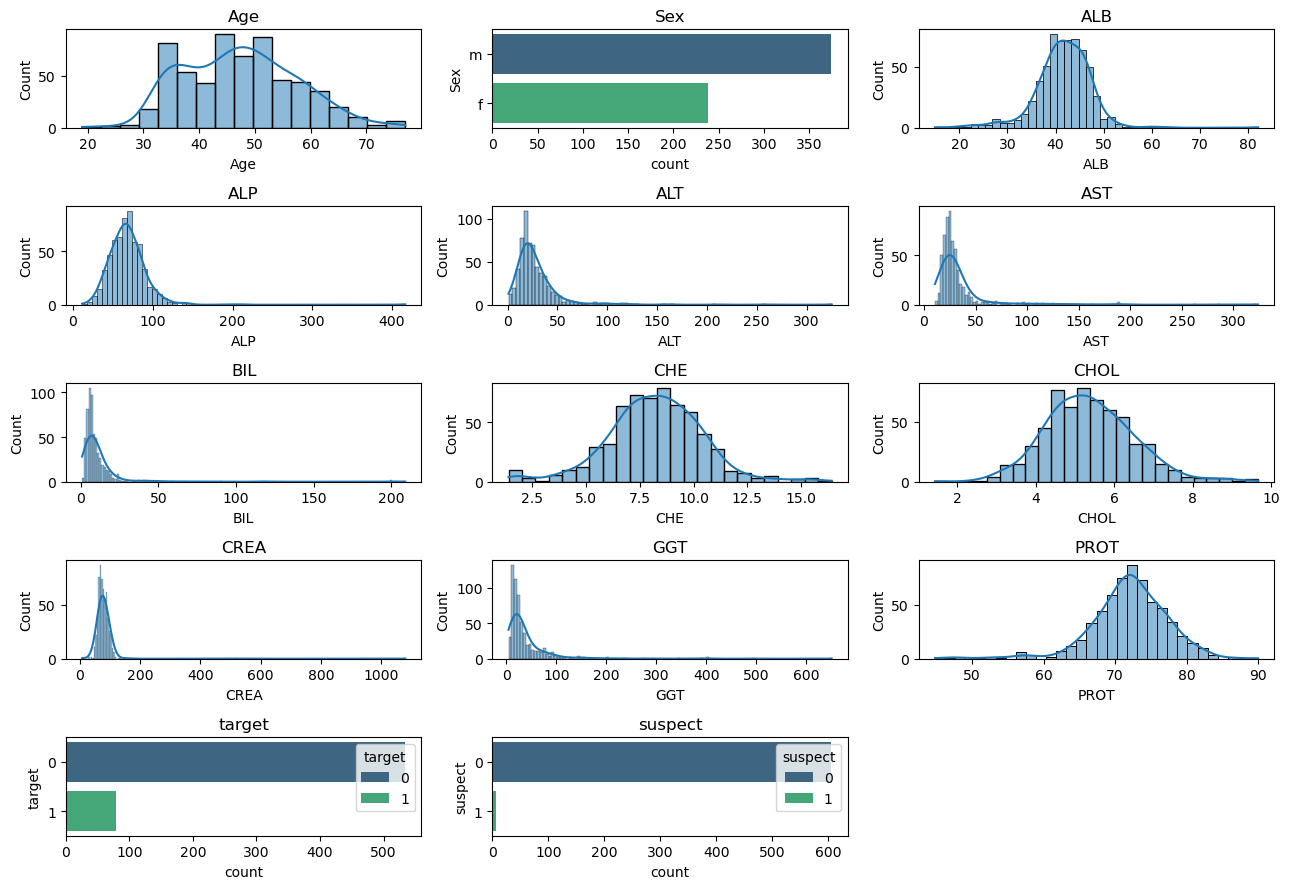

In [81]:
representacion_de_las_variables(df)

##### Boxplot para revisar outliers:

In [83]:
df.columns

Index(['Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA',
       'GGT', 'PROT', 'target', 'suspect'],
      dtype='object')

##### Determinamos una lista con las variables continuas

In [85]:
var_cont = []
for col in df.columns:
    if len(df[col].unique()) > 2:
        var_cont.append(col)

In [87]:
var_cont

['Age',
 'ALB',
 'ALP',
 'ALT',
 'AST',
 'BIL',
 'CHE',
 'CHOL',
 'CREA',
 'GGT',
 'PROT']

#### Procedemos a ver los outliers que se encuentran en el conjunto de datos, df

##### Procedemos a ver los outliers que se encuentran en las variables continuas

Usamos una funcion para graficar los outliers de las variables continuas

In [89]:
# Funcion para revisar los outliers

def plot_boxplot_with_outliers(data, column_name, outlier_color = 'red', factor = 1.5):
    # Calcular los estadísticos clave
    Q1 = data[column_name].quantile(0.25)
    Q3 = data[column_name].quantile(0.75)
    IQR = Q3 - Q1

    # Calcular los límites para los valores atípicos
    lower_bound = Q1 - factor * IQR
    upper_bound = Q3 + factor * IQR
    
    # Crear un gráfico de diagrama de caja (boxplot)
    plt.figure(figsize=(8,10))
    sns.boxplot(y=data[column_name], showfliers=False)

    # plt.title(f'Diagrama de Caja de {column_name}')
    plt.ylabel(column_name)
    plt.xlabel(i)
    
    # Resaltar los valores atípicos en un color diferente, por defecto está en color rojo
    outliers = data[(data[column_name] < lower_bound) | (data[column_name] > upper_bound)]
    plt.scatter(y=outliers[column_name], x=[0]*len(outliers), color=outlier_color, label='Outliers')

    # Anotar los valores de límites y cuartiles en el gráfico
    plt.text(0.35, Q1-0.55, f'Q1: {Q1:.2f}', fontsize=10)
    plt.text(0.35, Q3+0.3, f'Q3: {Q3:.2f}', fontsize=10)
    plt.text(0.205, lower_bound, f'Límite Inferior: {lower_bound:.2f}',fontsize=10)
    plt.text(0.205, upper_bound, f'Límite Superior: {upper_bound:.2f}',fontsize=10)
    plt.legend()
    plt.show()
    
    return outliers

In [91]:
# dataframe df que tiene solamente las variables continuas -> df_var_cont
df_var_cont = df[var_cont]
df_var_cont

,Age,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT
0,32,38.5,52.500000,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0
1,32,38.5,70.300000,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5
2,32,46.9,74.700000,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3
3,32,43.2,52.000000,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7
4,32,39.2,74.100000,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7
...,...,...,...,...,...,...,...,...,...,...,...
610,62,32.0,416.600000,5.9,110.3,50.0,5.57,6.30,55.7,650.9,68.5
611,64,24.0,102.800000,2.9,44.4,20.0,1.54,3.02,63.0,35.9,71.3
612,64,29.0,87.300000,3.5,99.0,48.0,1.66,3.63,66.7,64.2,82.0
613,46,33.0,67.787302,39.0,62.0,20.0,3.56,4.20,52.0,50.0,71.0


<Figure size 200x100 with 0 Axes>

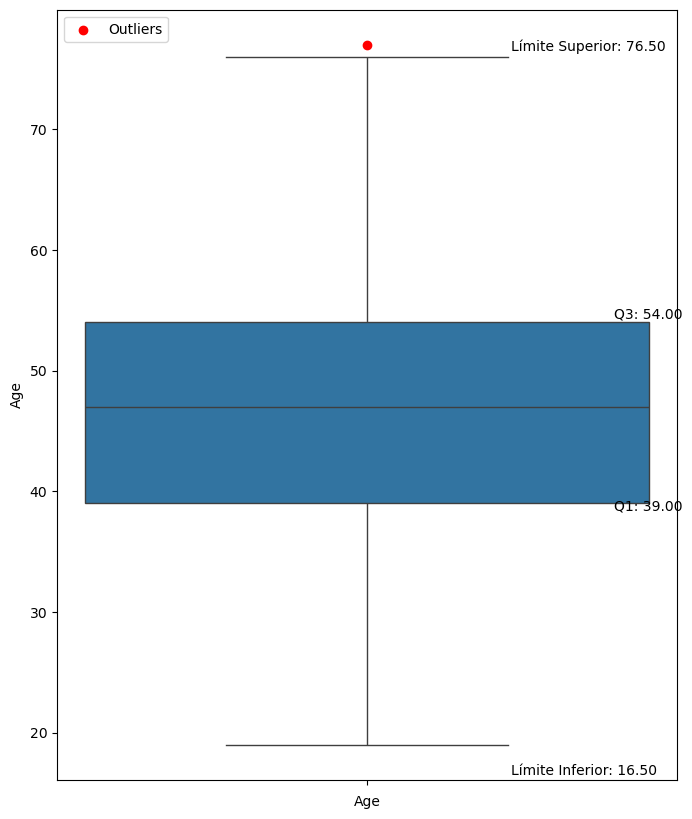

<Figure size 200x100 with 0 Axes>

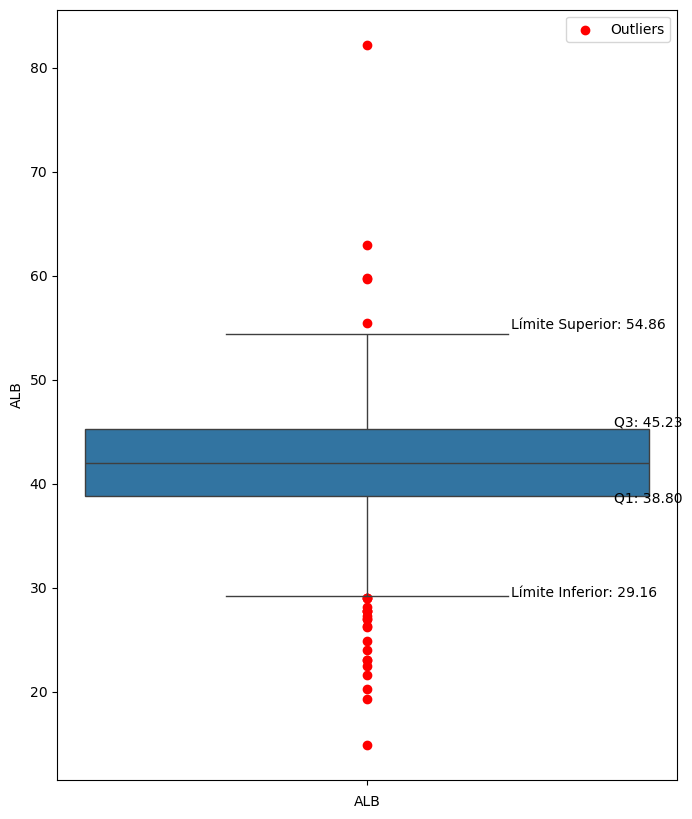

<Figure size 200x100 with 0 Axes>

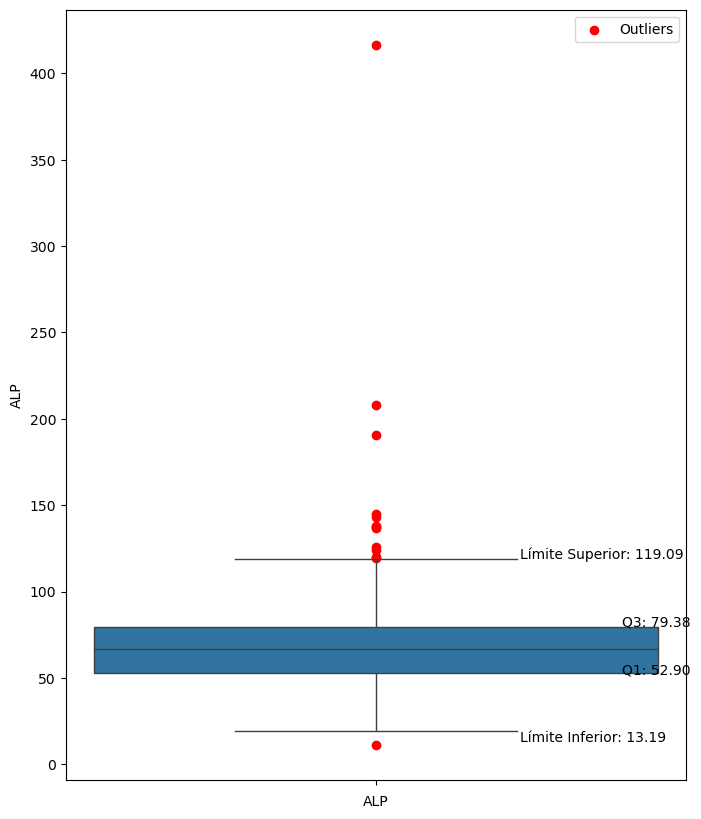

<Figure size 200x100 with 0 Axes>

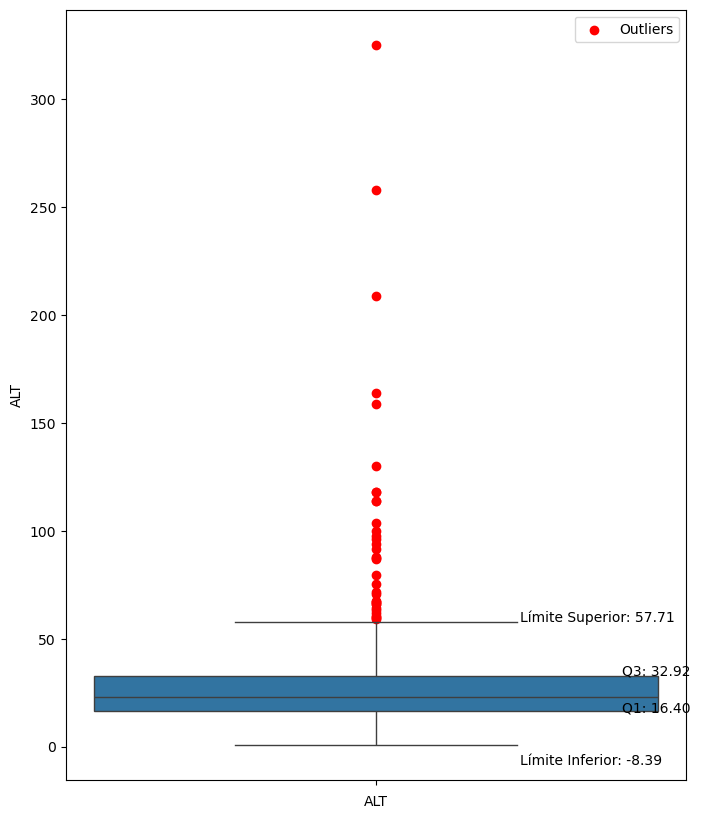

<Figure size 200x100 with 0 Axes>

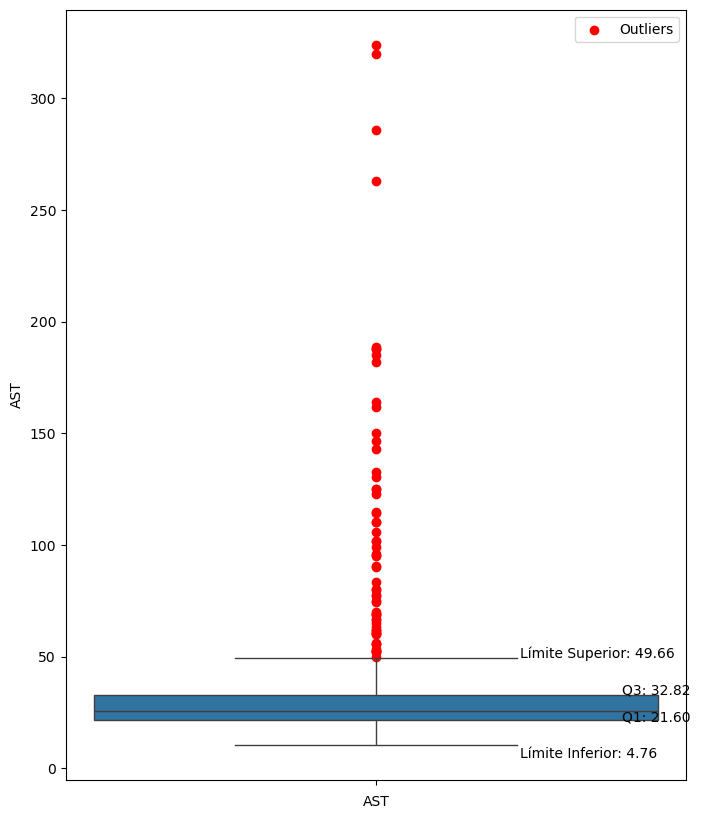

<Figure size 200x100 with 0 Axes>

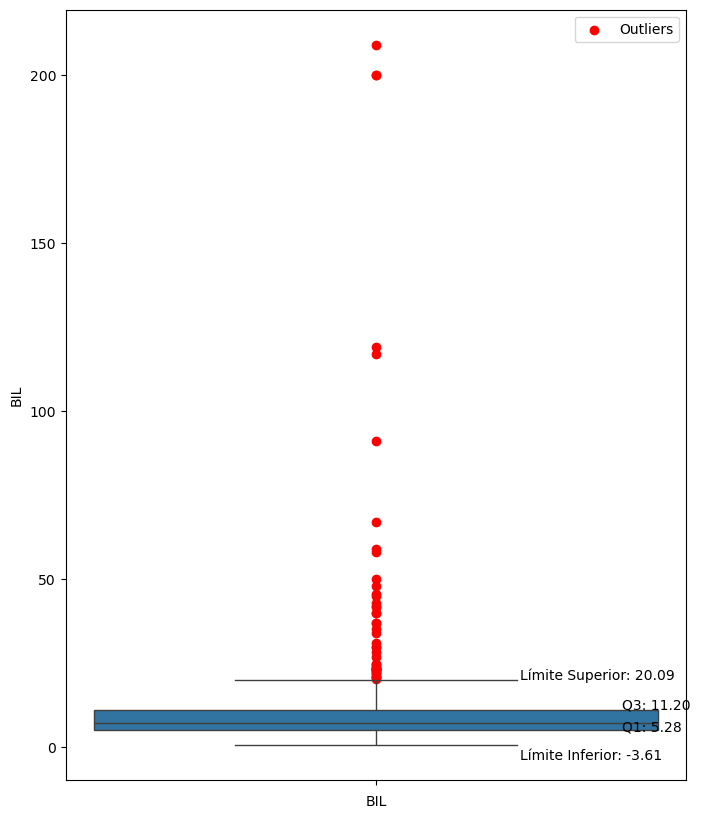

<Figure size 200x100 with 0 Axes>

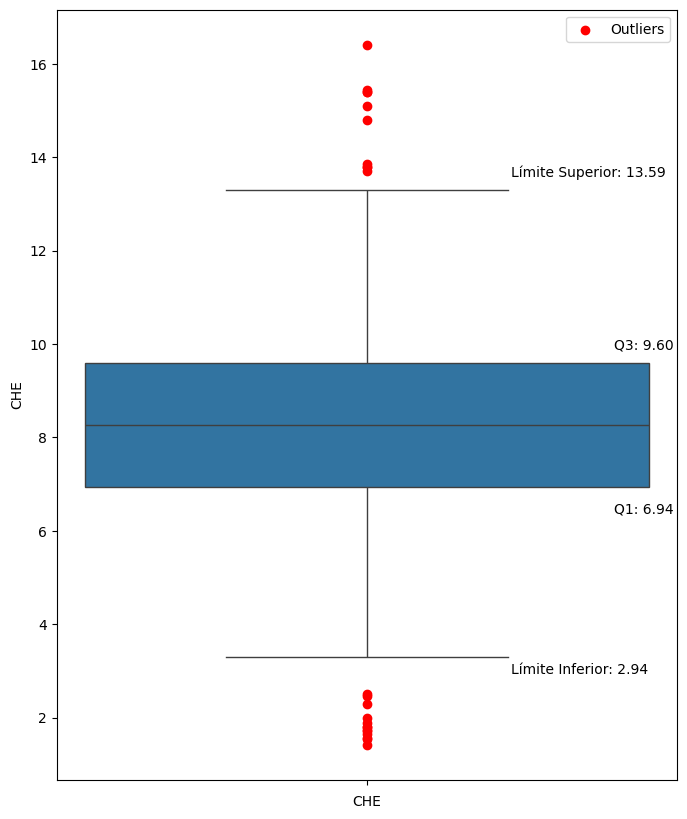

<Figure size 200x100 with 0 Axes>

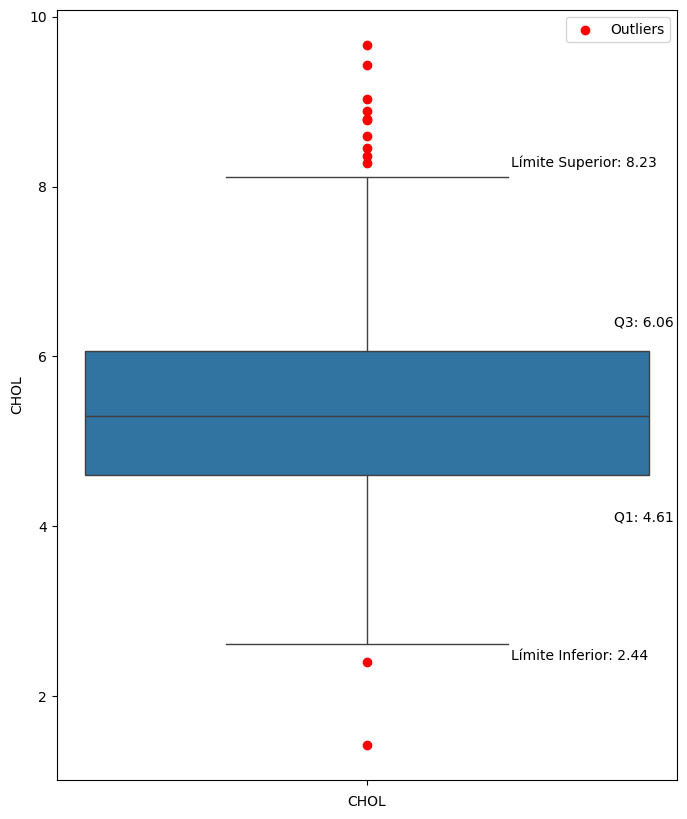

<Figure size 200x100 with 0 Axes>

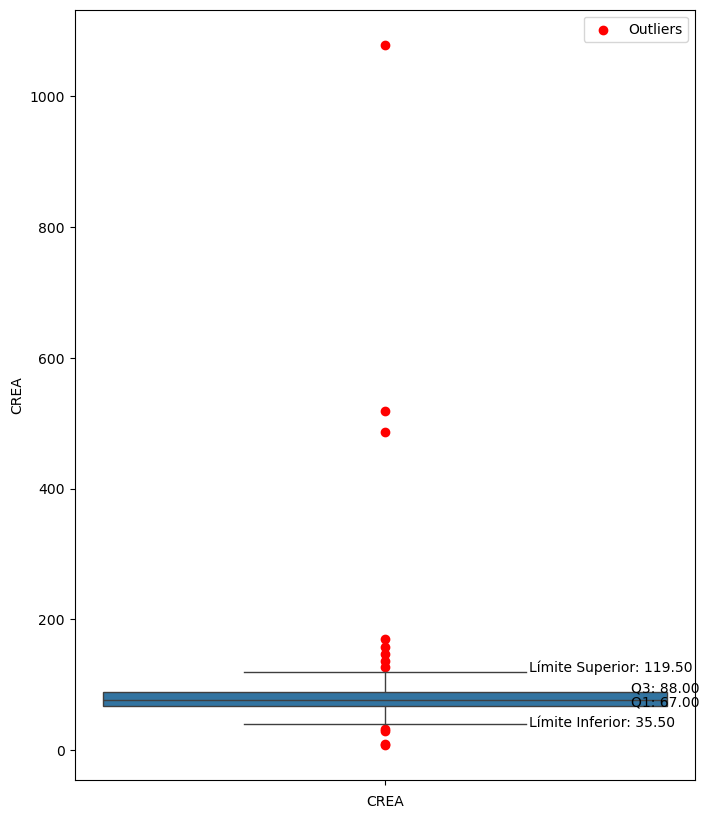

<Figure size 200x100 with 0 Axes>

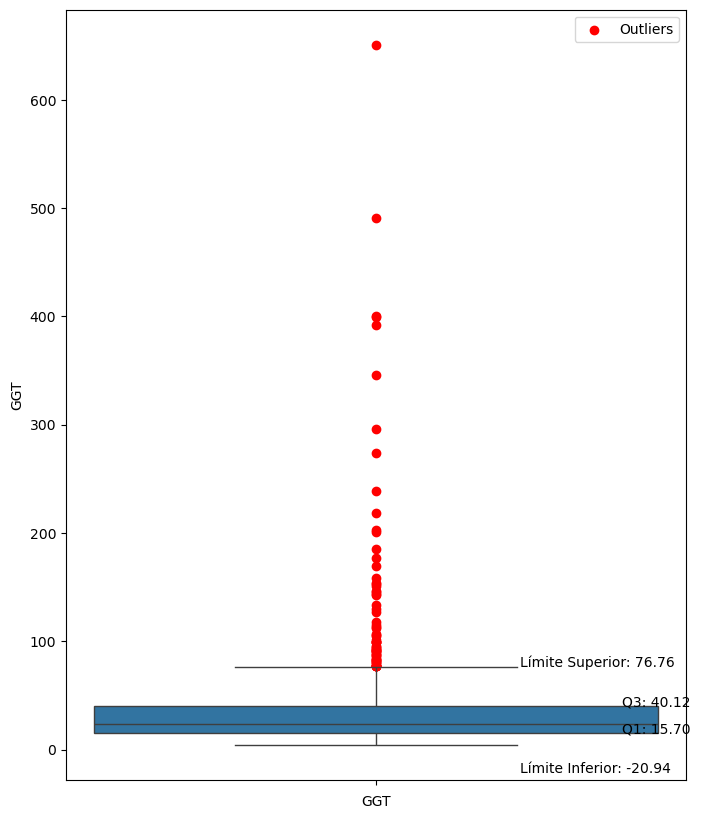

<Figure size 200x100 with 0 Axes>

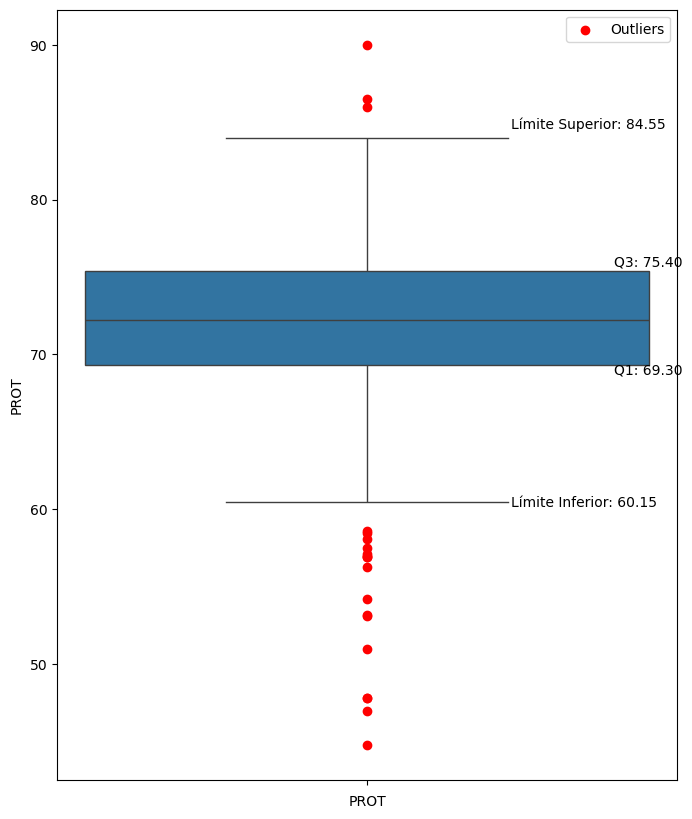

In [93]:
# Revision de los outliers de las variables continuas

for i in df_var_cont.columns:
    plt.figure(figsize=(2, 1))
    plot_boxplot_with_outliers(data = df, column_name = i, outlier_color = 'red', factor = 1.5)

In [95]:
Q1 = df[var_cont].quantile(0.25)
Q3 = df[var_cont].quantile(0.75)
IQR = Q3 - Q1
# Recuento de outliers como recuento
((df[var_cont] < (Q1 - 1.5 * IQR)) | (df[var_cont] > (Q3 + 1.5 * IQR))).sum()

Age      1
ALB     26
ALP     13
ALT     35
AST     62
BIL     46
CHE     23
CHOL    12
CREA    12
GGT     65
PROT    20
dtype: int64

In [97]:
# Recuento de outliers como %
((df[var_cont] < (Q1 - 1.5 * IQR)) | (df[var_cont] > (Q3 + 1.5 * IQR))).mean()

Age     0.001634
ALB     0.042484
ALP     0.021242
ALT     0.057190
AST     0.101307
BIL     0.075163
CHE     0.037582
CHOL    0.019608
CREA    0.019608
GGT     0.106209
PROT    0.032680
dtype: float64

In [99]:
df.head()

,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target,suspect
0,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0,0
1,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0,0
2,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0,0
3,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0,0
4,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0,0


In [101]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 612 entries, 0 to 614
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Age      612 non-null    int64  
 1   Sex      612 non-null    object 
 2   ALB      612 non-null    float64
 3   ALP      612 non-null    float64
 4   ALT      612 non-null    float64
 5   AST      612 non-null    float64
 6   BIL      612 non-null    float64
 7   CHE      612 non-null    float64
 8   CHOL     612 non-null    float64
 9   CREA     612 non-null    float64
 10  GGT      612 non-null    float64
 11  PROT     612 non-null    float64
 12  target   612 non-null    int32  
 13  suspect  612 non-null    int32  
dtypes: float64(10), int32(2), int64(1), object(1)
memory usage: 66.9+ KB


##### Heatmap que muestras la correlaciones entre las variables regresoras

Para hacer el heatmap, procedemos a incluir solamente las variables regresoras que sean de tipo float e int.

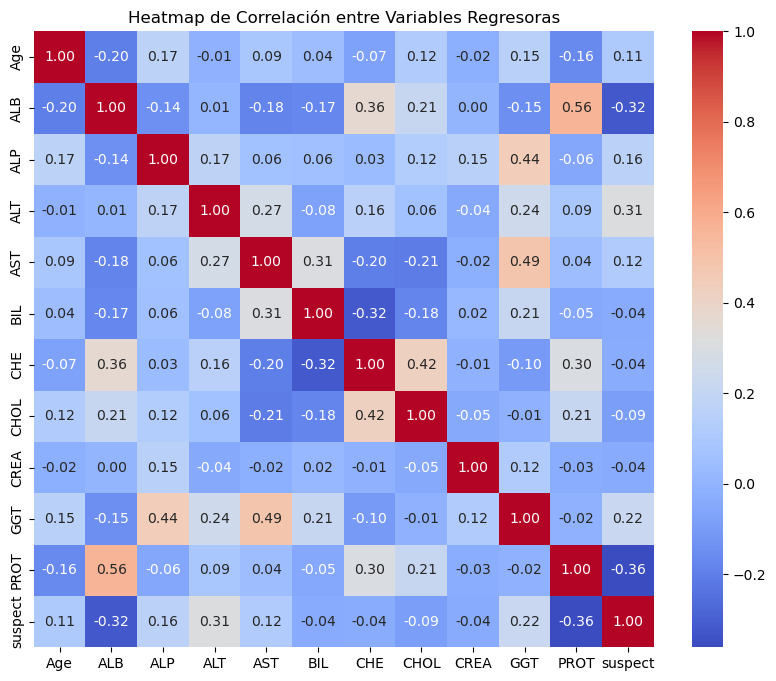

In [103]:
# Seleccionamos solamente las columnas regresoras númericas
# Por lo cual, seleccionamos solamente las columnas float e int y descartamos la variable objetivo la cual es target.
numeric_df = df.select_dtypes(include=[float, int]).drop(columns=['target'])

# Calculamos la matriz de correlación
correlation_matrix = numeric_df.corr()

# Creamos el heatmap de las correlaciones
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Heatmap de Correlación entre Variables Regresoras")
plt.show()

##### Otra manera de realizarlo

In [105]:
# Usamos la matriz de correlación del código anterior
corr = numeric_df.corr()
corr.style.background_gradient(cmap='coolwarm')

,Age,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,suspect
Age,1.000000,-0.199953,0.168295,-0.007046,0.088178,0.040160,-0.074764,0.121320,-0.021683,0.150489,-0.160994,0.109015
ALB,-0.199953,1.000000,-0.140005,0.009789,-0.181928,-0.170567,0.363820,0.208857,0.002534,-0.146497,0.560239,-0.324544
ALP,0.168295,-0.140005,1.000000,0.171322,0.061958,0.055821,0.033804,0.123516,0.149671,0.443403,-0.055613,0.163389
ALT,-0.007046,0.009789,0.171322,1.000000,0.269540,-0.075155,0.155223,0.063173,-0.044359,0.244663,0.093914,0.311652
AST,0.088178,-0.181928,0.061958,0.269540,1.000000,0.306612,-0.198990,-0.212056,-0.023837,0.487421,0.038863,0.118608
BIL,0.040160,-0.170567,0.055821,-0.075155,0.306612,1.000000,-0.315819,-0.180591,0.020782,0.208957,-0.048705,-0.039782
CHE,-0.074764,0.363820,0.033804,0.155223,-0.198990,-0.315819,1.000000,0.424361,-0.008008,-0.101588,0.299027,-0.035657
CHOL,0.121320,0.208857,0.123516,0.063173,-0.212056,-0.180591,0.424361,1.000000,-0.047414,-0.010010,0.209080,-0.087502
CREA,-0.021683,0.002534,0.149671,-0.044359,-0.023837,0.020782,-0.008008,-0.047414,1.000000,0.120016,-0.031530,-0.042199
GGT,0.150489,-0.146497,0.443403,0.244663,0.487421,0.208957,-0.101588,-0.010010,0.120016,1.000000,-0.015471,0.221359


##### Observaciones relevantes del heatmap
- Variables **ALB y PROT**: Existe una correlación positiva relevante entre estas 2 variables, lo que nos indica, que niveles más altos de albúmina, ALB, tiende a asociarse con mayores niveles de proteínas totales, PROT. Lo cual en realidad es correcto, debido a que un aumento en la albúmina generalmente contribuye a un aumento total en las proteínas.
- Varibales **ALT y AST**: Estas dos enzimas tienen una correlación positiva considerable debido a que ambas pueden indicar daño hepático. Además, ambas variables tienden a aumentar en situaciones de daño hepático, lo cual  indica su correlación.
- Variables **CHE y ALB/PROT**: La colinesterasa (CHE) tiene una correlación positiva moderada con la albúmina (ALB) y las proteínas totales (PROT), lo que podría indicar una relación entre la función hepática y la síntesis de proteinas, en especial con la ALB. La sintesís de proteína viene a ser el proceso mediante el cual las células producen proteinas a partir de la información genética contenida en el ADN.
- Variables **CHE y CHOL**: Podemos ver que la colinesterasa (CHE) tiene una correlación positiva significativa con el nivel de colesterol (CHOL), lo cual refleja la realidad, debido a que ambas variables están ligadas a procesos metabólicos y de salud hepática. De hecho, alteraciones en una de estas 2 variables puede indicar problemas métabolicos o hepáticos subyacentes. Entonce podemos decir que hay multicolinealidad entre ambas variables.
- Variables **GGT y AST**: Existe una correlación positiva significativa, debido a que ambas variables son enzimas hepáticas y se da su correlación debido a que cuando el higado se encuentra dañado o inflamado, es probable que aumenten ambas enzimas simultáneamente. Por lo cual, ambas variables podrían utilizarse para diagnosticar problemas hepáticos.

In [45]:
df.head()

,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,target,suspect
0,32,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0,0
1,32,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0,0
2,32,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0,0
3,32,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0,0
4,32,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0,0


#### Aportes adicionales a considerar

Debido a que la variable 'target' y 'suspect' se han determinado de una misma variable 'Category', veremos el nivel de asociación entre las variables usando **La Prueba de Chi-Cuadrado**. Lo cual me indicara el nivel de asociación entre las variables 'target' y 'suspect'

Se esta utilizando la prueba de chi-cuadrado porque ambas variables, 'target' y 'suspect', son variables binarias.

In [46]:
from scipy.stats import chi2_contingency

# Creamos la tabla de contingencia entre la variable regresora 'suspect' y la variable objetivo 'target'
tabla_contingencia = pd.crosstab(df['suspect'], df['target'])

# Prueba de Chi-cuadrado
chi2, p, dof, expected = chi2_contingency(tabla_contingencia)
print("Estadístico Chi-cuadrado:", chi2)
print("p-valor:", p)

Estadístico Chi-cuadrado: 40.259173872241874
p-valor: 2.2240849761688598e-10


##### Recordar lo siguiente del valor p

Un valor p pequeño (generalmente menor que 0.05) indica que puedes rechazar la hipótesis nula, lo que nos indica que hay una asociación significativa entre la variable regresora y la variable objetivo.

Ejemplo de interpretación:

- Si p < 0.05: Hay una asociación significativa entre las variables con un nivel de confianza del 95%.
- Si p < 0.01: Hay una asociación significativa con un nivel de confianza del 99%.
- Si p ≥ 0.05: No hay suficiente evidencia para afirmar que hay una asociación entre las varibles.


Por lo tanto, siendo el p-valor igual a 2.2240849761688598e-10, podemos indicar que hay una asociación significativa entre la variable 'suspect' y la variable 'target' 

1. Pregunta **f**
   
   f. Transforma las variables regresoras por medio de la estandarización. Muestra el antes y después de esta usando boxplots, y realiza una segmentación de la muestra en 33% para test y el resto para entrenamiento.

In [47]:
df.columns

Index(['Age', 'Sex', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA',
       'GGT', 'PROT', 'target', 'suspect'],
      dtype='object')

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 612 entries, 0 to 614
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Age      612 non-null    int64  
 1   Sex      612 non-null    object 
 2   ALB      612 non-null    float64
 3   ALP      612 non-null    float64
 4   ALT      612 non-null    float64
 5   AST      612 non-null    float64
 6   BIL      612 non-null    float64
 7   CHE      612 non-null    float64
 8   CHOL     612 non-null    float64
 9   CREA     612 non-null    float64
 10  GGT      612 non-null    float64
 11  PROT     612 non-null    float64
 12  target   612 non-null    int32  
 13  suspect  612 non-null    int32  
dtypes: float64(10), int32(2), int64(1), object(1)
memory usage: 66.9+ KB


In [49]:
var_cont

['Age',
 'ALB',
 'ALP',
 'ALT',
 'AST',
 'BIL',
 'CHE',
 'CHOL',
 'CREA',
 'GGT',
 'PROT']

##### Estandarizamos las variables continuas

In [50]:
# Procedemos a estandarizar las variables continuas

scaler = StandardScaler()

# var_cont -> lista de las variables continuas
df_scaled = scaler.fit_transform(df[var_cont])

# Coloca los datos en el DataFrame
df_scaled = pd.DataFrame(df_scaled, columns = var_cont)

In [51]:
df_scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     612 non-null    float64
 1   ALB     612 non-null    float64
 2   ALP     612 non-null    float64
 3   ALT     612 non-null    float64
 4   AST     612 non-null    float64
 5   BIL     612 non-null    float64
 6   CHE     612 non-null    float64
 7   CHOL    612 non-null    float64
 8   CREA    612 non-null    float64
 9   GGT     612 non-null    float64
 10  PROT    612 non-null    float64
dtypes: float64(11)
memory usage: 52.7 KB


In [52]:
# Coloco la columna suspect, la cual es binaria, por lo cual no era necesario estandarizarla
df_scaled['suspect'] = df['suspect']

# Coloco la variable objetivo en el dataframe, la cual no se estandariza
df_scaled['target'] = df['target']

In [55]:
# Convertimos las variables regresoras categoricas en dummy
df_dummy = pd.get_dummies(df.select_dtypes(['object']), dtype=int, drop_first=True)

In [56]:
# Procedemos a juntar los 2 dataframes df_scaled y df_dummy
df_concat = pd.concat([df_scaled, df_dummy], axis = 1)
df_concat.head(5)

,Age,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,suspect,target,Sex_m
0,-1.533722,-0.550964,-0.614863,-0.812461,-0.379878,-0.205131,-0.582446,-1.898592,0.496645,-0.498726,-0.565687,0.0,0.0,1.0
1,-1.533722,-0.550964,0.078247,-0.407746,-0.301052,-0.415827,1.352217,-0.503814,-0.145698,-0.434542,0.826465,0.0,0.0,1.0
2,-1.533722,0.918274,0.249577,0.307382,0.544813,-0.287068,0.289065,-0.148456,0.095181,-0.111786,1.346202,0.0,0.0,1.0
3,-1.533722,0.271109,-0.634332,0.087343,-0.364719,0.462075,-0.399931,-0.557117,-0.025259,-0.100783,0.677969,0.0,0.0,1.0
4,-1.533722,-0.428528,0.226214,0.165928,-0.298020,-0.082224,0.430514,-0.930243,-0.105552,-0.172303,-0.621373,0.0,0.0,1.0


In [57]:
# Procedemos a visualizar que se haya dodo correctamente la estandarizacion de las variables regresoras.
df_concat.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 615 entries, 0 to 614
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Age      612 non-null    float64
 1   ALB      612 non-null    float64
 2   ALP      612 non-null    float64
 3   ALT      612 non-null    float64
 4   AST      612 non-null    float64
 5   BIL      612 non-null    float64
 6   CHE      612 non-null    float64
 7   CHOL     612 non-null    float64
 8   CREA     612 non-null    float64
 9   GGT      612 non-null    float64
 10  PROT     612 non-null    float64
 11  suspect  609 non-null    float64
 12  target   609 non-null    float64
 13  Sex_m    612 non-null    float64
dtypes: float64(14)
memory usage: 67.4 KB


In [58]:
# Eliminamos los valores nulos restantes.
df_concat = df_concat.dropna()

In [59]:
df_concat.info()

<class 'pandas.core.frame.DataFrame'>
Index: 609 entries, 0 to 611
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Age      609 non-null    float64
 1   ALB      609 non-null    float64
 2   ALP      609 non-null    float64
 3   ALT      609 non-null    float64
 4   AST      609 non-null    float64
 5   BIL      609 non-null    float64
 6   CHE      609 non-null    float64
 7   CHOL     609 non-null    float64
 8   CREA     609 non-null    float64
 9   GGT      609 non-null    float64
 10  PROT     609 non-null    float64
 11  suspect  609 non-null    float64
 12  target   609 non-null    float64
 13  Sex_m    609 non-null    float64
dtypes: float64(14)
memory usage: 71.4 KB


##### Antes de estandarizar las variables, mostramos un boxplot de las variables continuas con sus respectivos outliers, en caso tengan.

In [60]:
# teniamos las variables continuas en la siguiente lista
print(var_cont)
# Y habíamos definido un dataframe solamente con las variables continuas (a partir del datafrane df)
print(df_var_cont.head())

['Age', 'ALB', 'ALP', 'ALT', 'AST', 'BIL', 'CHE', 'CHOL', 'CREA', 'GGT', 'PROT']
   Age   ALB   ALP   ALT   AST   BIL    CHE  CHOL   CREA   GGT  PROT
0   32  38.5  52.5   7.7  22.1   7.5   6.93  3.23  106.0  12.1  69.0
1   32  38.5  70.3  18.0  24.7   3.9  11.17  4.80   74.0  15.6  76.5
2   32  46.9  74.7  36.2  52.6   6.1   8.84  5.20   86.0  33.2  79.3
3   32  43.2  52.0  30.6  22.6  18.9   7.33  4.74   80.0  33.8  75.7
4   32  39.2  74.1  32.6  24.8   9.6   9.15  4.32   76.0  29.9  68.7


<Figure size 200x100 with 0 Axes>

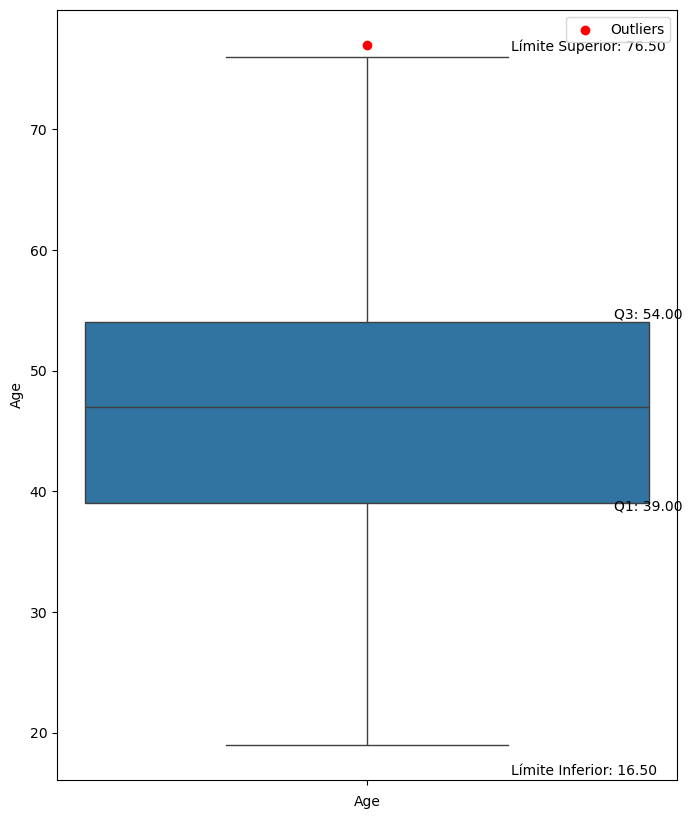

<Figure size 200x100 with 0 Axes>

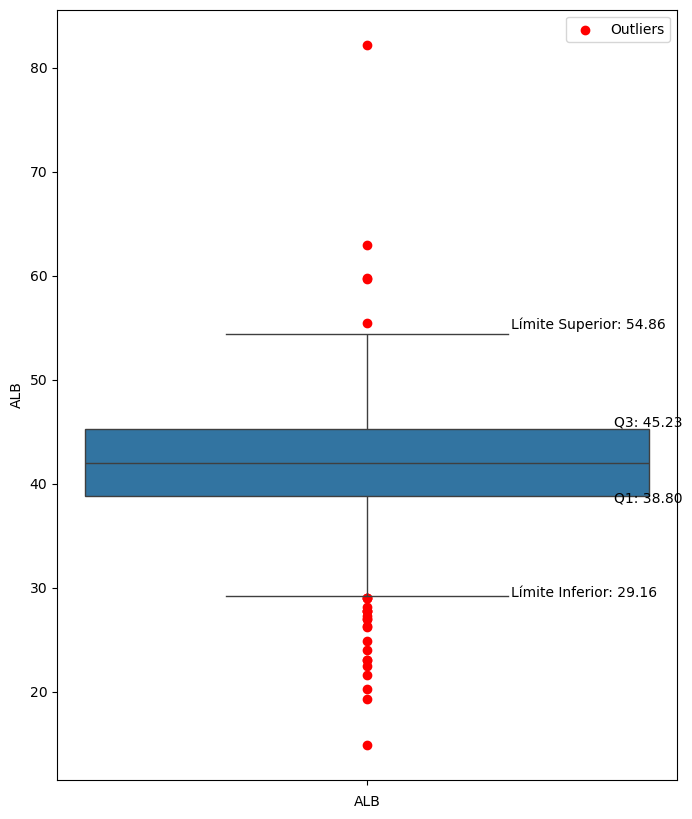

<Figure size 200x100 with 0 Axes>

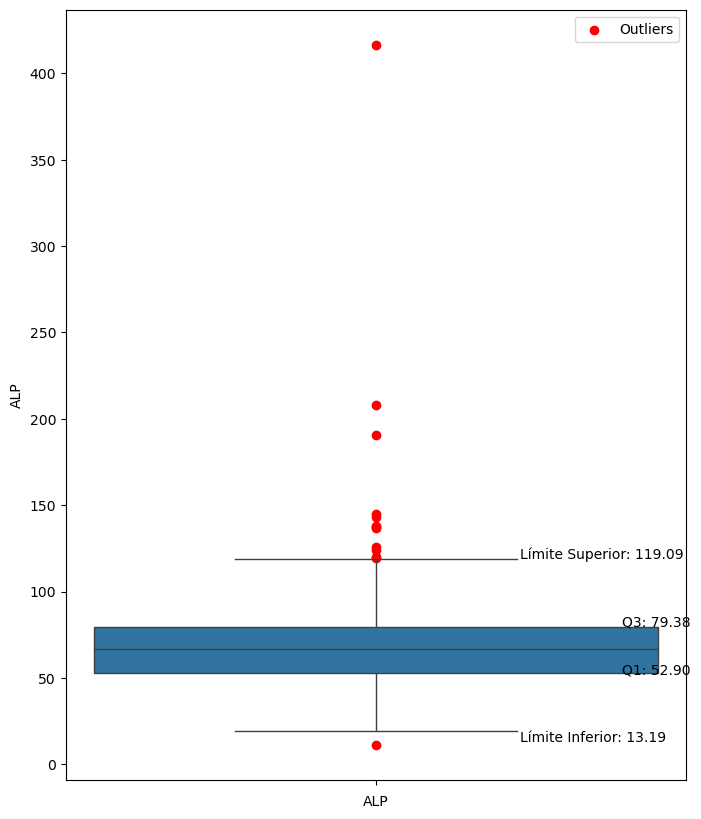

<Figure size 200x100 with 0 Axes>

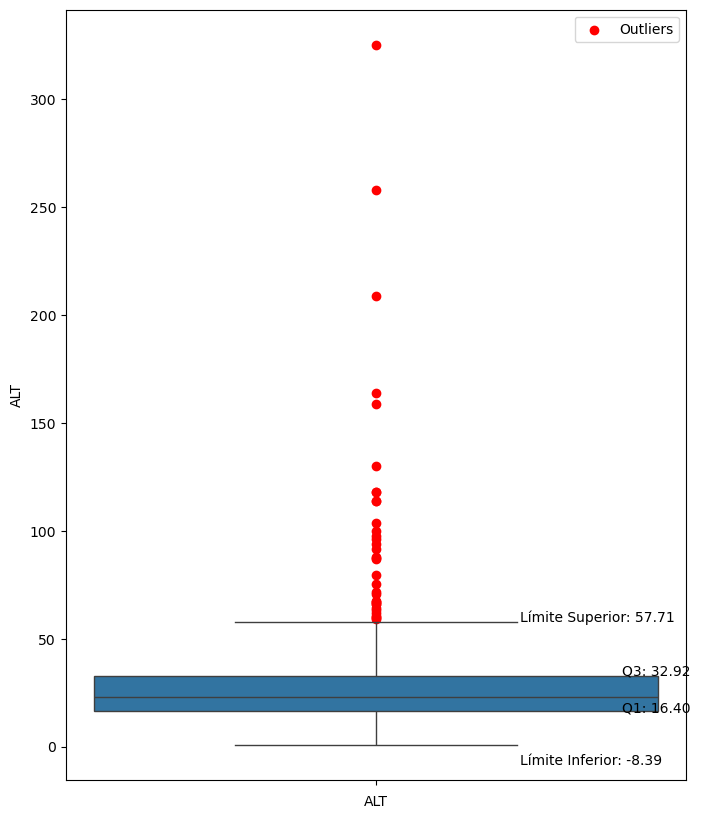

<Figure size 200x100 with 0 Axes>

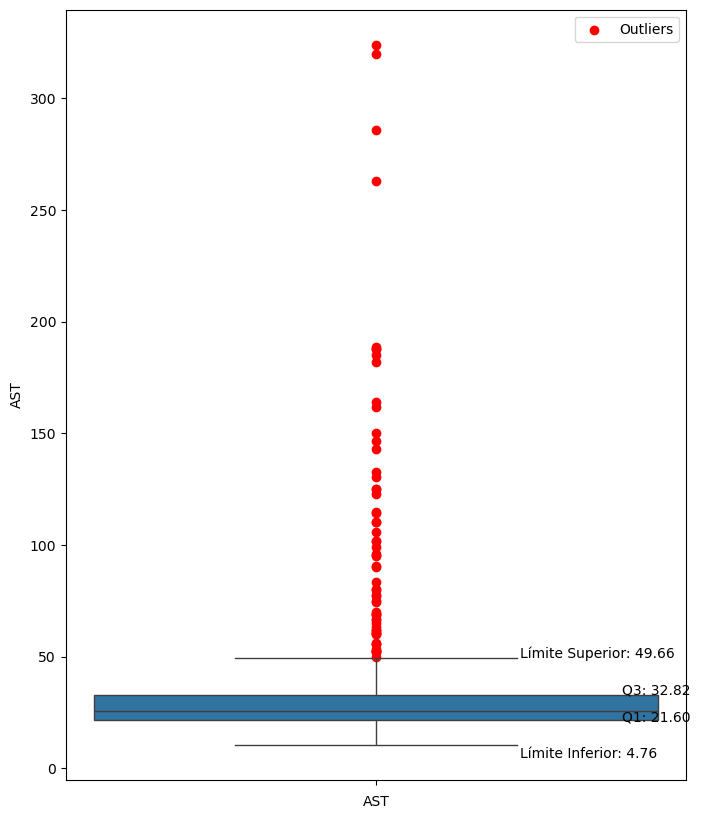

<Figure size 200x100 with 0 Axes>

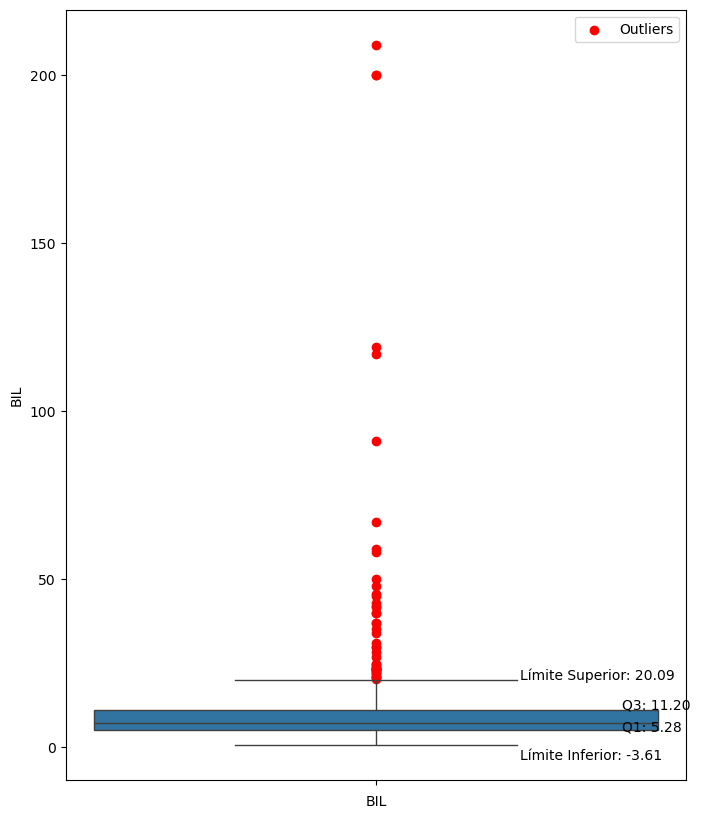

<Figure size 200x100 with 0 Axes>

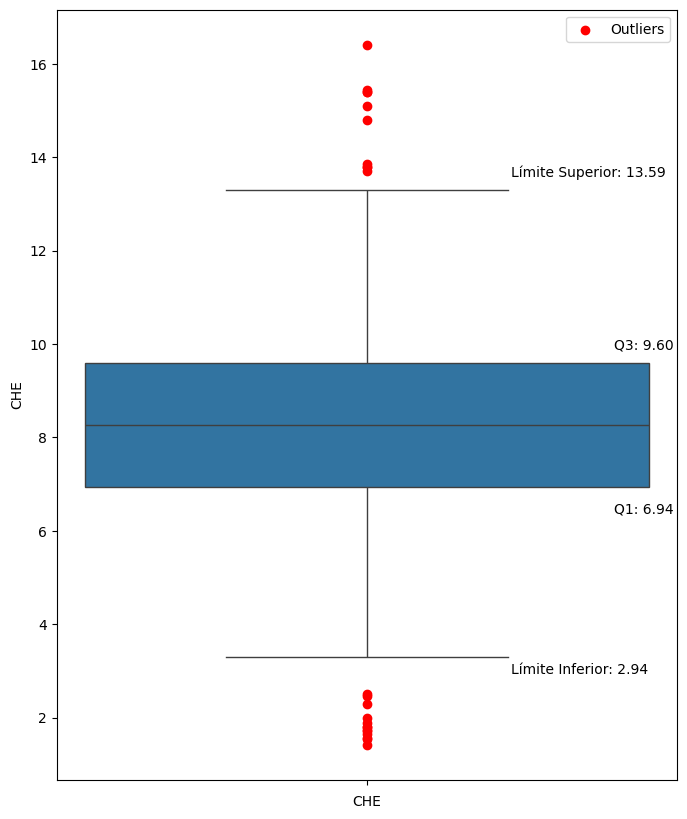

<Figure size 200x100 with 0 Axes>

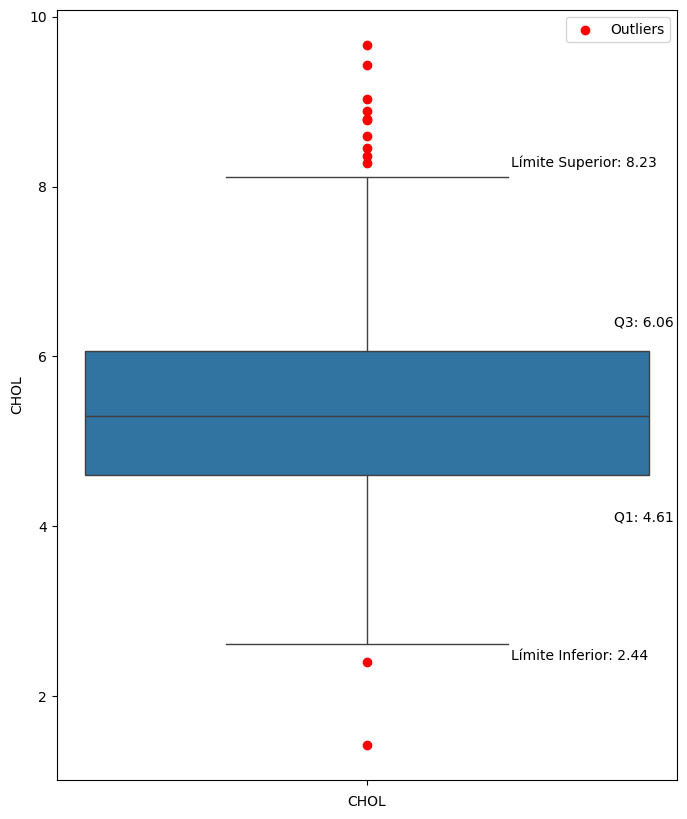

<Figure size 200x100 with 0 Axes>

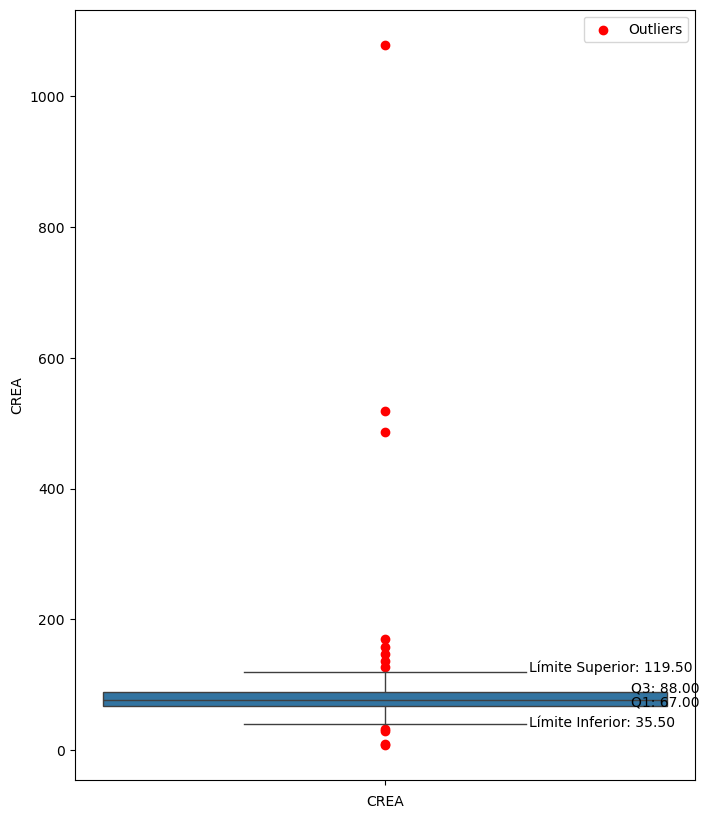

<Figure size 200x100 with 0 Axes>

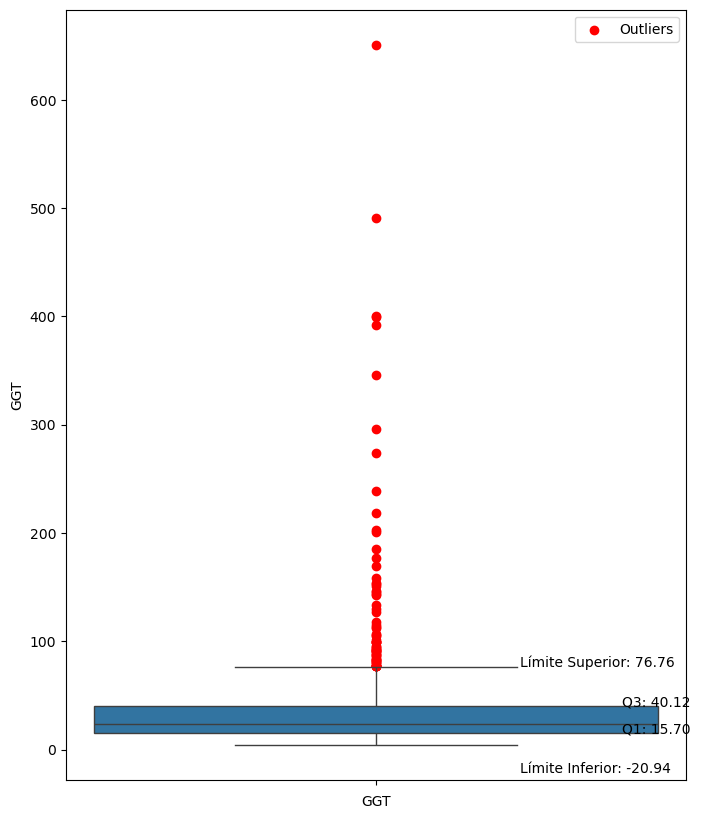

<Figure size 200x100 with 0 Axes>

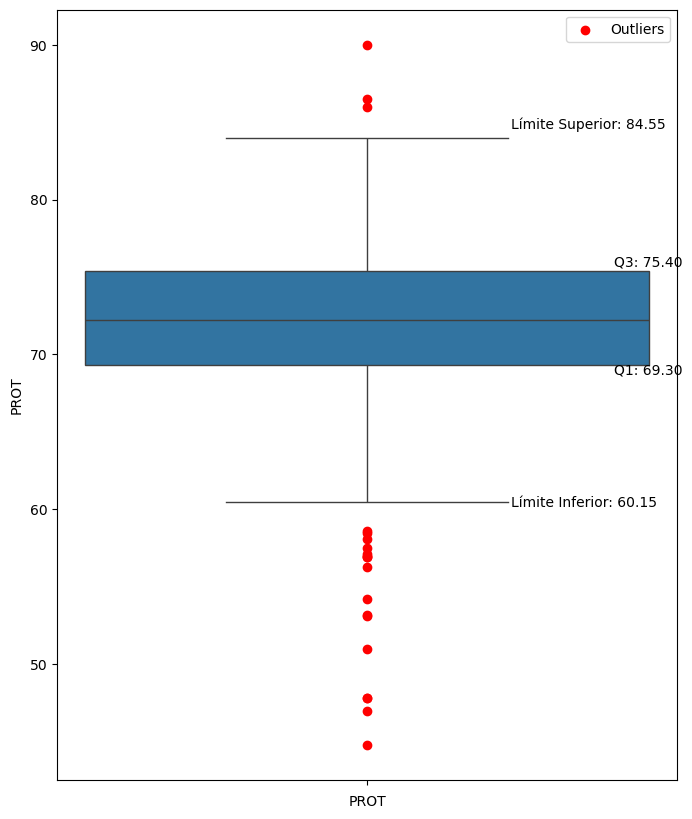

In [61]:
# Por lo cual mostramos un boxplot de las variables continuas y con sus respectivos outliers
for i in df_var_cont.columns:
    plt.figure(figsize=(2, 1))
    plot_boxplot_with_outliers(data = df, column_name = i, outlier_color = 'red', factor = 1.5)

##### Depues de haber estandarizado las variables, mostramos un boxplot de las variables continuas con sus respectivos outliers, en caso tengan.

<Figure size 200x100 with 0 Axes>

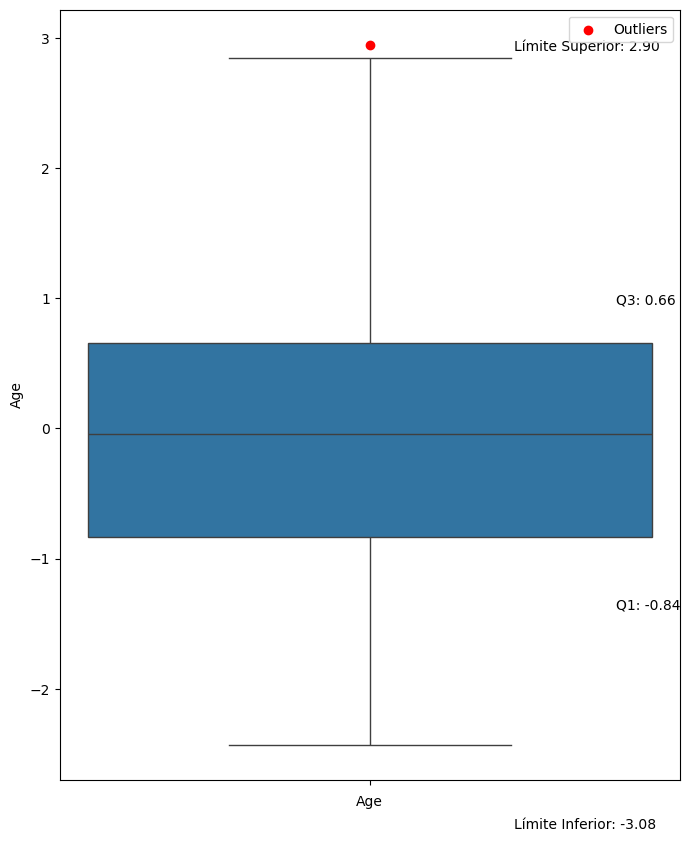

<Figure size 200x100 with 0 Axes>

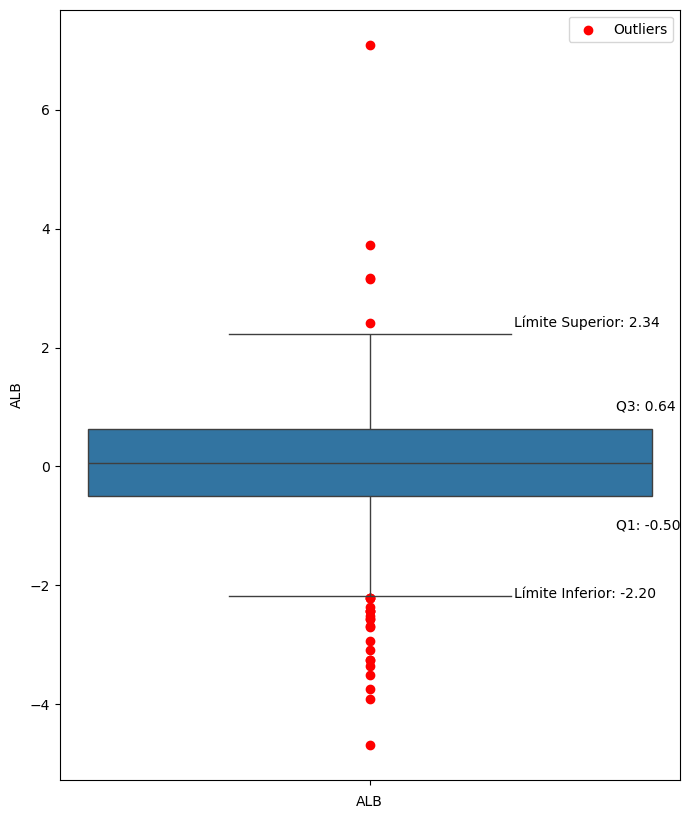

<Figure size 200x100 with 0 Axes>

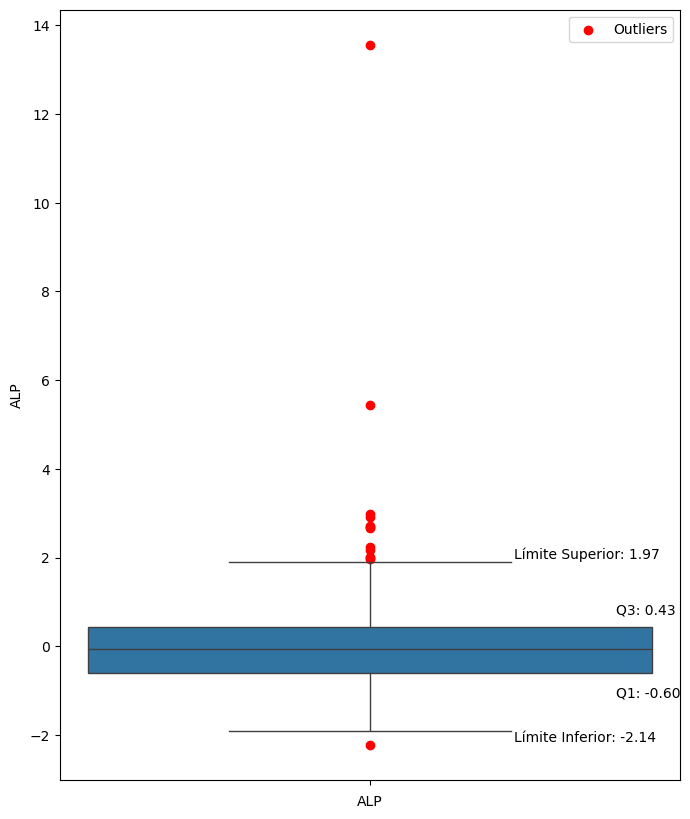

<Figure size 200x100 with 0 Axes>

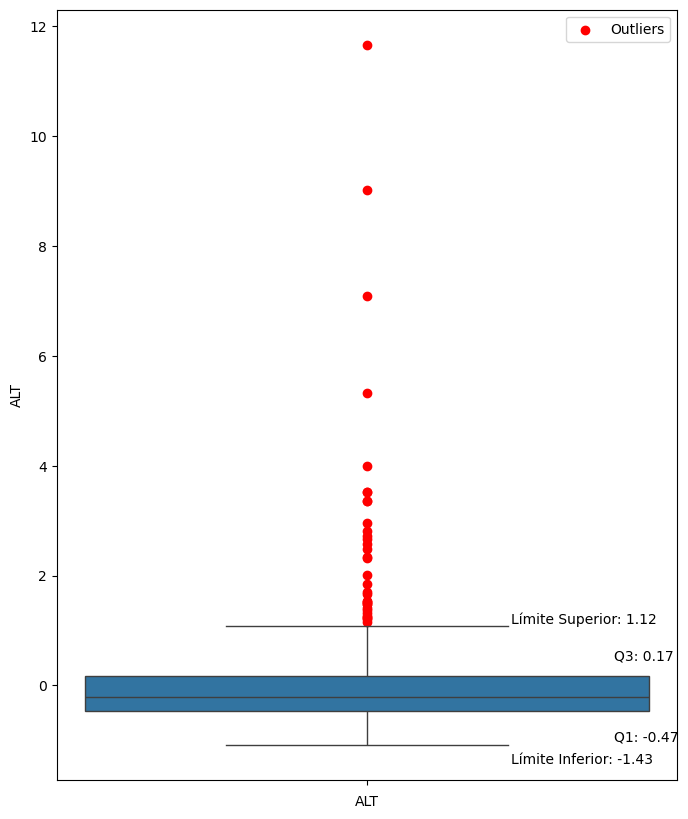

<Figure size 200x100 with 0 Axes>

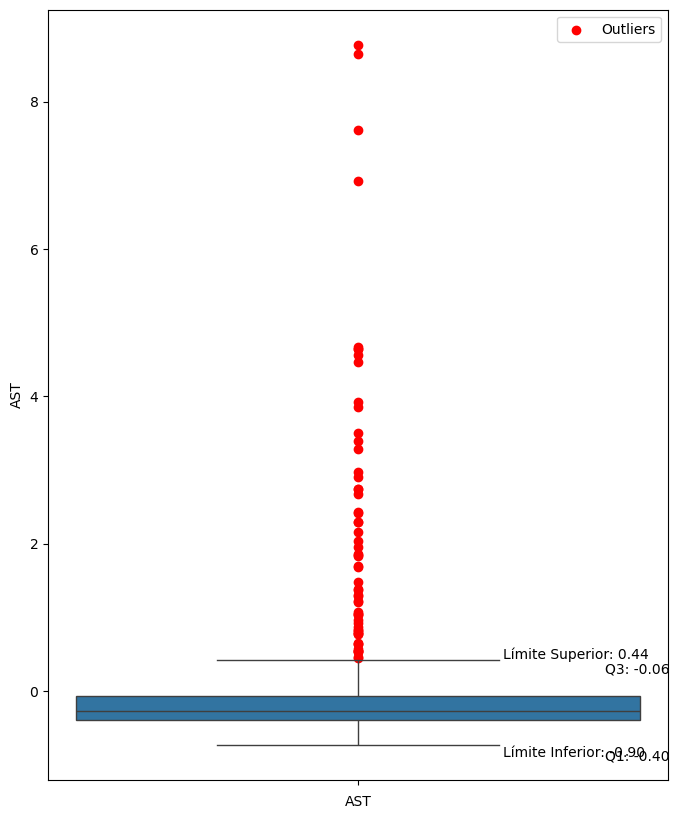

<Figure size 200x100 with 0 Axes>

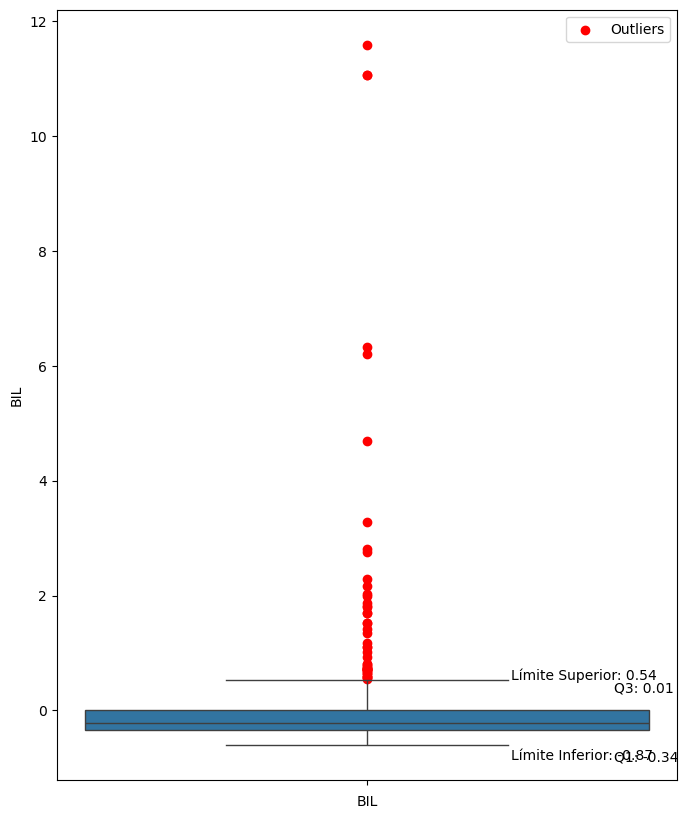

<Figure size 200x100 with 0 Axes>

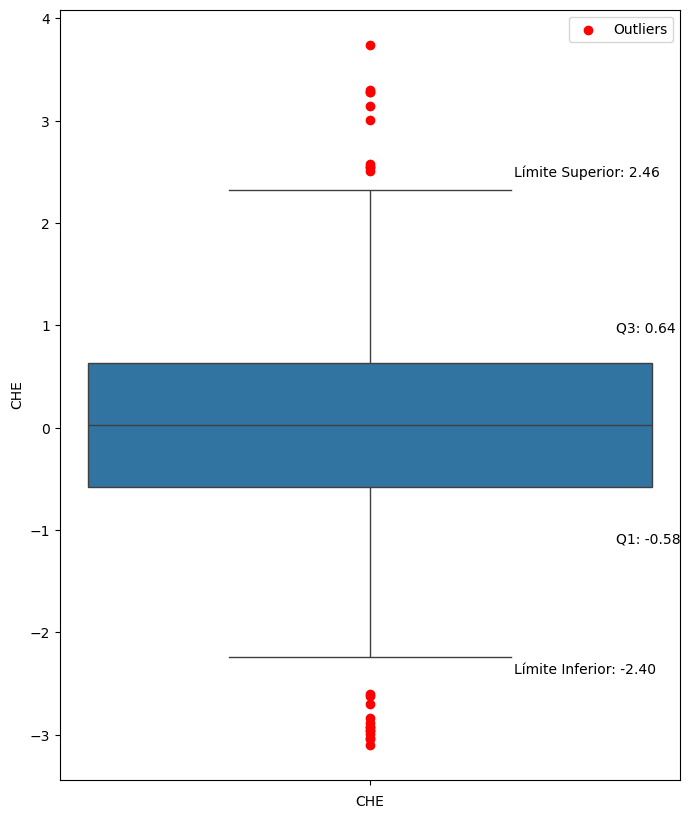

<Figure size 200x100 with 0 Axes>

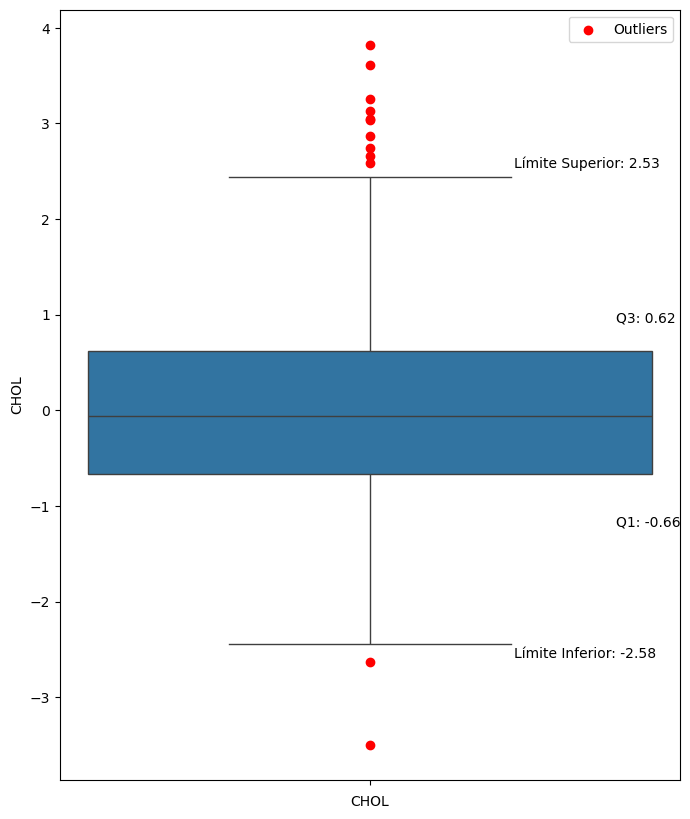

<Figure size 200x100 with 0 Axes>

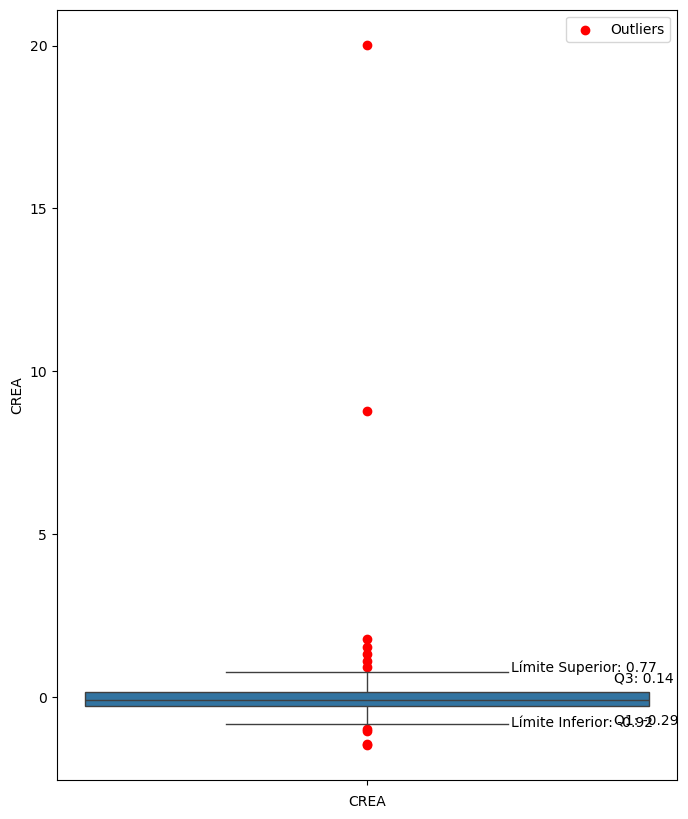

<Figure size 200x100 with 0 Axes>

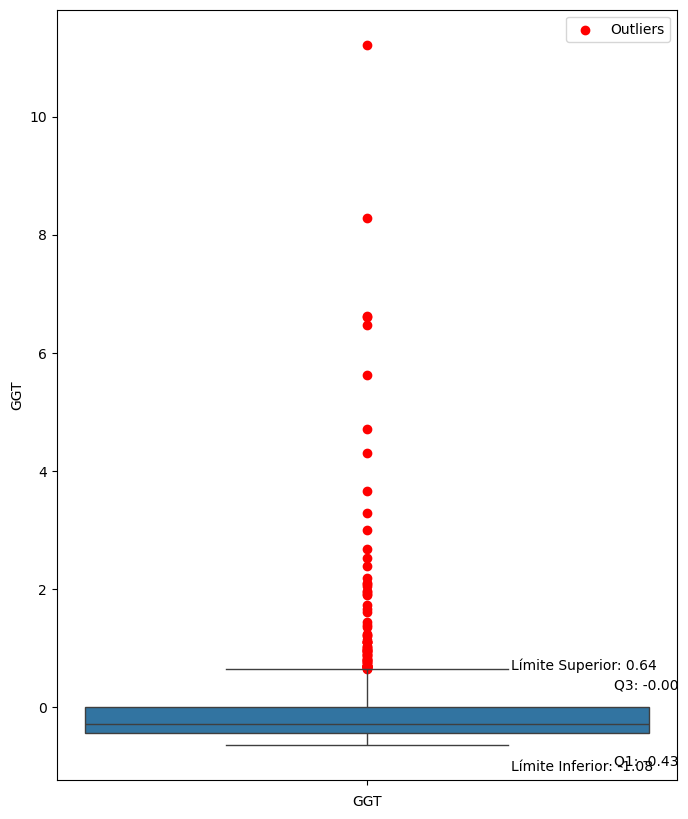

<Figure size 200x100 with 0 Axes>

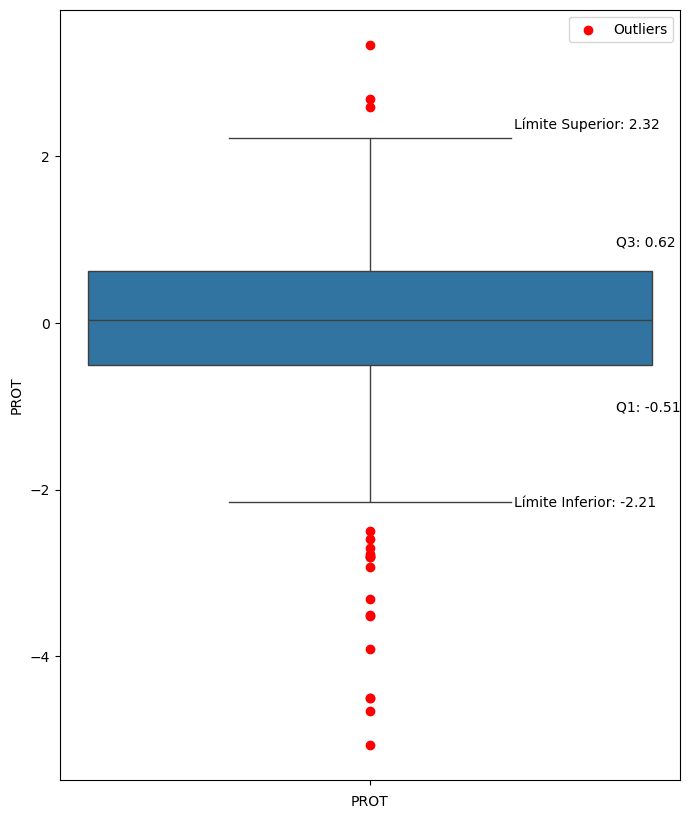

In [62]:
# dataframe estandarizado con las variables continuas
df_concat_cont = df_concat[var_cont]

# Por lo cual mostramos un boxplot de las variables continuas y con sus respectivos outliers
for i in df_concat_cont.columns:
    plt.figure(figsize=(2, 1))
    plot_boxplot_with_outliers(data = df_concat, column_name = i, outlier_color = 'red', factor = 1.5)

##### Realizamos una segmentación de la muestra en 33% para test y el resto para entrenamiento

In [63]:
# Descartamos la variable objetivo 'target' y además descartamos la variable 'suspect' 
# debido a su alta correlacion con la variable target.
X = df_concat.drop(columns=['target', 'suspect'])
y = df_concat['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.67, random_state=1234)

In [64]:
# Mostramos las dimensiones de los conjuntos de entrenamiento y prueba
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((408, 12), (201, 12), (408,), (201,))

#### Pregunta 2

2. Desarrolla un modelo regresión logística con validación cruzada usando 5-fold, con regularización Elastic Net. Busca para los siguientes hiper parámetros:

- Cs: valores entre 0.01 y 5.0, con 200 valores lineales.
- l1_ratio: valores entre 0 y 1, con 200 valores lineales.

Muestra los valores óptimos encontrados, y las métricas precisión, recall, f1-score y accuracy. Describe cuáles son las tres características con mayor incidencia en la predicción de sujeto o muestra con sangre con posible enfermedad.

In [65]:
# Configuramos el modelo de regresión logística
log_reg = LogisticRegression(
    max_iter=1000, 
    solver='saga', 
    tol=0.01, 
    penalty='elasticnet'
)

# Definimos la grilla de hiperparámetros
param_grid = {
    'C': np.linspace(0.01, 5.0, 200),
    'l1_ratio': np.linspace(0, 1, 200)
}

# Configuramos GridSearchCV para encontrar la mejor combinación de hiperparámetros
grid_search = GridSearchCV(log_reg, param_grid, cv=5, n_jobs=12)

# Entrenamos el modelo
grid_search.fit(X_train, y_train)

# Obtenemos el mejor modelo encontrado por GridSearchCV (entrena un modelo con los mejores hiper parámetros encontrados)
best_model = grid_search.best_estimator_

# Realizamos las predicciones en el conjunto de prueba
y_pred = best_model.predict(X_test)

Cabe señalar que en vez de usar LogisticRegression() se pudo haber utilizado LogisticRegressionCV() pero finalmente se realizó el código con LogisticRegression() por una mayor compresión que el otro que no se había usado en clase. Se debío haber utilizado LogisticRegressionCV() porque está optimizado para Elastic Net y además tiene una mayor eficiencia y simplicidad.

##### Explicación:
coef_importance = pd.Series(best_model.coef_[0], index=X_train.columns).abs().sort_values(ascending=False)

- Es una serie que contiene los coeficientes del modelo de regresión logística con Elastic Net, estos coeficiente reflejan la importancia de cada característica con la variable objetivo.
- El indice de esta serie está conformado por cada característica de X_train y se encuentra emparejado con su importancia.
- Por otro lado, esta serie se encuentra ordenada de la característica más importante a la menos importante por medio de haberlo ordenado mediante el código .sort_values(ascending=False), que me ordena la serie de mayor a menor valor.
- Al colocar .abs() se obtiene el valor absoluto de cada coeficiente, y se ha hecho así porque solamente quiero medir la magnitud de la influencia de cada característica, sin preocuparme por la dirección ya sea esta positiva o negativa

In [66]:
# Mejores valores de hiper parámetros encontrados
best_params = grid_search.best_params_

# Calculamos las métricas de rendimiento del modelo
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)

# Calculamos la incidencia de cada una de las caracteristicas
coef_importance = pd.Series(best_model.coef_[0], index=X_train.columns).abs().sort_values(ascending=False)

# Mostramos las métricas de evaluación
print(f"Mejores valores de hiper parámetros encontrados: {best_params}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}\n")

# Mostramos las 3 caracteristicas con mayor incidencia
print("Las 3 caracteristicas con mayor incidencia son: \n", coef_importance.head(3))

Mejores valores de hiper parámetros encontrados: {'C': 0.33597989949748747, 'l1_ratio': 0.2663316582914573}
Precision: 1.0000
Recall: 0.6154
F1 Score: 0.7619
Accuracy: 0.9502

Las 3 caracteristicas con mayor incidencia son: 
 AST    1.250862
GGT    1.034509
BIL    0.706557
dtype: float64


##### A considerar:
Se utilizo un max_iter=1000 por facilidad, debido a que al poner un max_iter = 5000 hubiera tardado mucho más tiempo el modelo en cargar.

##### Podemos indicar lo siguiente sobre el modelo de regresión logística con regularización elastic net

El modelo tiene un muy buen accuracy con un 95% y una precisión de 100%, lo que te indica que tiene un muy buen rendimiento e indentifica bien la mayoría de los casos positivos. Sin embargo, posee un recall de 61.54%, lo cual es bajo. Lo cual indica que se le escapan casos positivos.

Las variables más importantes para el modelo son AST, GGT y BIL las cuales están relacionadas en señalar daño hepático. GGT es importante debido a que indica daño hepático en relación con el consumo del alcohol. Por otro lado, los niveles de AST y BIL suelen aumentar cuando existe un daño hepático.

En conclusión, podemos indicar que el modelo tiene un buen desempeño sin embargo, se podrían tomar medidas para mejorar las métricas de recall y f1 score que no son buenas.

#### Pregunta 3

3. Implementa un modelo Extreme Gradient Boosting con búsqueda de hiper parámetros de grilla, con regularización para la combinación L1 y L2. Considera para esto:

- a. reg_lambda: valores entre 0.0 y 2.0, con 10 valores lineales.
- b. reg_alpha: valores entre 0 y 1, con 10 valores lineales.
- c. learning_rate: valores entre 0.1 a 10, con 20 valores lineales.

In [67]:
xgb_clf = XGBClassifier(random_state=1234, use_label_encoder=False, eval_metric='logloss')

# Definir los parámetros para la búsqueda en grilla
param_grid = {
    'reg_lambda': np.linspace(0.0, 2.0, 10),       # Regularización L2
    'reg_alpha': np.linspace(0, 1, 10),            # Regularización L1
    'learning_rate': np.linspace(0.1, 10, 20)      # Tasa de aprendizaje
}

# Configuramos la búsqueda en grilla con validación cruzada
grid_search_xgb = GridSearchCV(estimator=xgb_clf, param_grid=param_grid, scoring='f1', cv=5, n_jobs=-1)

# Entrenamos el modelo
grid_search_xgb.fit(X_train, y_train)

# Obtenemos el mejor modelo encontrado por GridSearchCV (entrena un modelo con los mejores hiper parámetros encontrados)
best_model_xgb = grid_search_xgb.best_estimator_

# Realizamos las predicciones en el conjunto de prueba
y_pred_xgb = best_model_xgb.predict(X_test)

C:\Users\josek\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [17:38:28] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0ed59c031377d09b8-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


#### Pregunta 4

4. Muestra el nivel de importancia de los atributos, los valores óptimos de los hiper parámetros y las métricas precisión, recall, f1-score y accuracy. Compara los resultados de este modelo con el de regresión logística.

##### Sobre el mejor modelo encontrado por GridSearchCV del modelo Extreme Gradient Boosting, procedemos a realizar lo siguiente:

##### Mostramos el nivel de importancia de los atributos

In [68]:
# Dataframe con la importancia de los atributos

# datos con la importancia de cada variable
feature_importances = best_model_xgb.feature_importances_

# nombre de las variables
feature_names = X_train.columns

# Generamos un DataFrame con las columnas del X_train y con sus respectivas importancias
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Ordenamos el DataFrame
importance_df = importance_df.sort_values(by='Importance', ascending=False)

In [69]:
print("Mostramos el nivel de importancia de los atributos\n")
importance_df

Mostramos el nivel de importancia de los atributos



,Feature,Importance
4,AST,0.647657
3,ALT,0.112905
9,GGT,0.068677
5,BIL,0.040057
8,CREA,0.038787
7,CHOL,0.035363
2,ALP,0.020819
6,CHE,0.014185
1,ALB,0.012588
10,PROT,0.004908


##### Mostramos los valores óptimos de los hiper parámetros y las métricas precisión, recall, f1-score y accuracy

In [70]:
# Calculamos los mejores valores de los hiper parámetros encontrados
best_params_xgb = grid_search_xgb.best_params_

# Calculamos las métricas de rendimiento del modelo
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)

# Mostramos las métricas de evaluación
print(f"Mejores valores de hiper parámetros encontrados: {best_params_xgb}\n")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall: {recall_xgb:.4f}")
print(f"F1 Score: {f1_xgb:.4f}")
print(f"Accuracy: {accuracy_xgb:.4f}\n")


Mejores valores de hiper parámetros encontrados: {'learning_rate': 0.6210526315789474, 'reg_alpha': 1.0, 'reg_lambda': 0.8888888888888888}
Precision: 0.9000
Recall: 0.6923
F1 Score: 0.7826
Accuracy: 0.9502



##### Podemos indicar lo siguiente sobre el modelo Extreme Gradient Boosting con búsqueda de hiper parámetros de grilla y con regularización para la combinación L1 y L2

El modelo tiene un muy buen accuracy con un 95% y una precisión de 90%, lo que te indica que tiene un muy buen rendimiento e indentifica bien la mayoría de los casos positivos. Sin embargo, posee un recall de 69.23%, lo cual sigue siendo bajo pero relativamente mejor al anterior. Sin embargo, debemos de considerar que aún se le escapan casos positivos.

Por otro lado, las 3 variables más importantes para el modelo son AST, ALT y GGT las cuales están relacionadas en señalar daño hepático. AST y ALT (Aspartato aminotransferasa y Alanina aminotransferasa) son enzimas que están relacionadas con el metabolismo hepático y suelen estar en niveles altos cuando hay daño hepático.

En conclusión, podemos indicar que el modelo tiene un buen desempeño. Sin embargo, se podrían tomar medidas para mejorar las métricas de recall y f1 score que son bajas.

##### Compara los resultados de este modelo con el de regresión logística.

##### Modelo de regresión logística con regularización elastic net

In [71]:
# Mostramos las métricas de evaluación
print(f"Mejores valores de hiper parámetros encontrados: {best_params}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}\n")

# Mostramos las 3 caracteristicas con mayor incidencia
print("Las 3 caracteristicas con mayor incidencia son: \n", coef_importance.head(3))

Mejores valores de hiper parámetros encontrados: {'C': 0.33597989949748747, 'l1_ratio': 0.2663316582914573}
Precision: 1.0000
Recall: 0.6154
F1 Score: 0.7619
Accuracy: 0.9502

Las 3 caracteristicas con mayor incidencia son: 
 AST    1.250862
GGT    1.034509
BIL    0.706557
dtype: float64


##### Modelo Extreme Gradient Boosting con búsqueda de hiper parámetros de grilla y con regularización para la combinación L1 y L2

In [72]:
# Mostramos las métricas de evaluación
print(f"Mejores valores de hiper parámetros encontrados: {best_params_xgb}")
print(f"Precision: {precision_xgb:.4f}")
print(f"Recall: {recall_xgb:.4f}")
print(f"F1 Score: {f1_xgb:.4f}")
print(f"Accuracy: {accuracy_xgb:.4f}\n")

print("Mostramos el nivel de importancia de los atributos\n")
print(importance_df.head(3))

Mejores valores de hiper parámetros encontrados: {'learning_rate': 0.6210526315789474, 'reg_alpha': 1.0, 'reg_lambda': 0.8888888888888888}
Precision: 0.9000
Recall: 0.6923
F1 Score: 0.7826
Accuracy: 0.9502

Mostramos el nivel de importancia de los atributos

  Feature  Importance
4     AST    0.647657
3     ALT    0.112905
9     GGT    0.068677


##### Conclusiones

Podemos señalar que ambos modelos tienen métricas de accuracy y precision muy buenas, sin embargo recall al ser una métrica que indica que tan bien el modelo detecta los casos positivos, lo vuelve una métrica crucial al considerar que estamos tratando con un problema de detección de enfermedades y esto se debe a que la detección de los casos positivos al diagnosticar una enfermedad es crucial y se quiere minimizar la cantidad de falsos negativos debido a que puede tener consecuencias muy graves, como es el caso que al paciente se le trate con diferentes procesos y medicamentos los cuales no funcionaran para curar la enfermedad y/o genere que el paciente se ponga más grave.

Por lo cual, podemos indicar que tomando **recall** como una métrica muy importante en este caso y además al ser el **F1 Score** más alto, podemos indicar que el Modelo de Extreme Gradient Boosting con búsqueda de hiper parámetros con grilla es el modelo a usar para dignosticar si el paciente tiene daño hepático al ser su F1 Score y Recall más alto que el Modelo de Regresión Logística con regularización elastic net.

Por otro lado, podemos señalar que las variables AST y GGT al estar presente como las variables más importantes en ambos modelos toman una buena relevancia en la predicciones de los modelos. Por lo cual, vendrían a ser las 2 primeras variables a tomar en cuenta y evaluar al momento de ver cómo está el higado del paciente y si posiblemente padece de una enfermedad.